# Análisis y predicción de cancelaciones hoteleras

Cuaderno de desarrollo del proyecto. Incluye limpieza, exploración, comparación de modelos y búsqueda de hiperparámetros de XGBoost.

**Sobre esta edición:** las rutas personales se reemplazaron por una carpeta local de trabajo. Las salidas conservadas son históricas y no proceden de una nueva ejecución. Consulta `docs/technical-notes.md` antes de interpretar las métricas. La aplicación de Hugging Face tiene un preprocesamiento distinto que debe unificarse con el entrenamiento.


In [ ]:
from pathlib import Path

# Ejecutable desde la raíz del repositorio o desde notebooks/.
WORK_DIR = Path.cwd()
PROJECT_ROOT = WORK_DIR.parent if WORK_DIR.name == "notebooks" else WORK_DIR
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
print("Archivos intermedios:", ARTIFACTS_DIR)


# Data Collect

In [ ]:
# Las carpetas se configuran en la primera celda; no se necesita montar Google Drive.


In [ ]:
# Importar paquetes
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# https://raw.githubusercontent.com/JuanTF/BPA---Datasets/refs/heads/main/hotel_bookings.csv
# /content/drive/MyDrive/Ciclo9/Grupo 2 - BPA/1° Trabajo parcial/hotel_bookings.csv
dataframe = pd.read_csv("https://raw.githubusercontent.com/JuanTF/BPA---Datasets/refs/heads/main/hotel_bookings.csv")
dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 33 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Hotel                        119390 non-null  object 
 1   IsCanceled                   119390 non-null  int64  
 2   LeadTime                     119357 non-null  float64
 3   ArrivalDateYear              119387 non-null  float64
 4   ArrivalDateMonth             119387 non-null  object 
 5   ArrivalDateWeekNumber        119386 non-null  float64
 6   ArrivalDateDayOfMonth        119385 non-null  float64
 7   StaysInWeekendNights         119385 non-null  float64
 8   StaysInWeekNights            119385 non-null  float64
 9   Adults                       119385 non-null  float64
 10  Children                     119381 non-null  float64
 11  Babies                       119385 non-null  float64
 12  Meal                         119361 non-null  object 
 13 

In [ ]:
dataframe.columns

Index(['Hotel', 'IsCanceled', 'LeadTime', 'ArrivalDateYear',
       'ArrivalDateMonth', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth',
       'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children',
       'Babies', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel',
       'IsRepeatedGuest', 'PreviousCancellations',
       'PreviousBookingsNotCanceled', 'ReservedRoomType', 'AssignedRoomType',
       'BookingChanges', 'DepositType', 'Agent', 'Company',
       'DaysInWaitingList', 'CustomerType', 'ADR', 'RequiredCarParkingSpaces',
       'TotalOfSpecialRequests', 'ReservationStatus', 'ReservationStatusDate',
       'IsHighSeason'],
      dtype='object')

In [ ]:
dataframe.shape

(119390, 33)

# Data Quality & Cleaning

1. Renombrar Columnas
2. Cambiar tipo de dato
3. Eliminar valores constantes
4. Eliminar filas duplicadas
5. Eliminar con mayor cantidad de columnas nulas

## 1. Renombrar Columnas

In [ ]:
columnas_renombrar = {
    'Hotel': 'hotel',
    'IsCanceled': 'is_canceled',
    'LeadTime': 'lead_time',
    'ArrivalDateYear': 'arrival_date_year',
    'ArrivalDateMonth': 'arrival_date_month',
    'ArrivalDateWeekNumber': 'arrival_date_week_number',
    'ArrivalDateDayOfMonth': 'arrival_date_day_of_month',
    'StaysInWeekendNights': 'stays_in_weekend_nights',
    'StaysInWeekNights': 'stays_in_week_nights',
    'Adults': 'adults',
    'Children': 'children',
    'Babies': 'babies',
    'Meal': 'meal',
    'Country': 'country',
    'MarketSegment': 'market_segment',
    'DistributionChannel': 'distribution_channel',
    'IsRepeatedGuest': 'is_repeated_guest',
    'PreviousCancellations': 'previous_cancellations',
    'PreviousBookingsNotCanceled': 'previous_bookings_not_canceled',
    'ReservedRoomType': 'reserved_room_type',
    'AssignedRoomType': 'assigned_room_type',
    'BookingChanges': 'booking_changes',
    'DepositType': 'deposit_type',
    'Agent': 'agent',
    'Company': 'company',
    'DaysInWaitingList': 'days_in_waiting_list',
    'CustomerType': 'customer_type',
    'ADR': 'adr',
    'RequiredCarParkingSpaces': 'required_car_parking_spaces',
    'TotalOfSpecialRequests': 'total_of_special_requests',
    'ReservationStatus': 'reservation_status',
    'ReservationStatusDate': 'reservation_status_date',
    'IsHighSeason': 'is_high_season',
}

dataframe.rename(columns=columnas_renombrar, inplace=True)

In [ ]:
dataframe.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'is_high_season'],
      dtype='object')

In [ ]:
dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 33 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119357 non-null  float64
 3   arrival_date_year               119387 non-null  float64
 4   arrival_date_month              119387 non-null  object 
 5   arrival_date_week_number        119386 non-null  float64
 6   arrival_date_day_of_month       119385 non-null  float64
 7   stays_in_weekend_nights         119385 non-null  float64
 8   stays_in_week_nights            119385 non-null  float64
 9   adults                          119385 non-null  float64
 10  children                        119381 non-null  float64
 11  babies                          119385 non-null  float64
 12  meal            

## 2. Cambiar tipo de dato

In [ ]:
columnas_castear = {
    'hotel': 'category',
    'is_canceled': 'category',
    'arrival_date_year': 'category',
    'arrival_date_month': 'category',
    'market_segment': 'category',
    'distribution_channel': 'category',
    'is_repeated_guest': 'category',
    'reserved_room_type': 'category',
    'assigned_room_type': 'category',
    'deposit_type': 'category',
    'customer_type': 'category',
    'reservation_status': 'category',
    'reservation_status_date':'datetime64[ns]',
    'is_high_season': 'category'
}

dataframe =dataframe.astype(columnas_castear)

In [ ]:
dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 33 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   hotel                           119390 non-null  category      
 1   is_canceled                     119390 non-null  category      
 2   lead_time                       119357 non-null  float64       
 3   arrival_date_year               119387 non-null  category      
 4   arrival_date_month              119387 non-null  category      
 5   arrival_date_week_number        119386 non-null  float64       
 6   arrival_date_day_of_month       119385 non-null  float64       
 7   stays_in_weekend_nights         119385 non-null  float64       
 8   stays_in_week_nights            119385 non-null  float64       
 9   adults                          119385 non-null  float64       
 10  children                        119381 non-null  float64

## 3. Eliminar valores constantes

In [ ]:
dataframe.nunique().sort_values(ascending=True)

,0
is_high_season,1
hotel,2
is_repeated_guest,2
is_canceled,2
deposit_type,3
reservation_status,3
arrival_date_year,3
customer_type,4
distribution_channel,4
children,5


In [ ]:
dataframe.drop(columns = 'is_high_season', inplace=True)

In [ ]:
dataframe.nunique().sort_values(ascending=True)

,0
hotel,2
is_canceled,2
is_repeated_guest,2
arrival_date_year,3
deposit_type,3
reservation_status,3
customer_type,4
distribution_channel,4
children,5
meal,5


## 4. Eliminar filas duplicadas

In [ ]:
dataframe[dataframe.duplicated()]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date


In [ ]:
dataframe.shape

(87409, 32)

In [ ]:
dataframe.duplicated().sum()

np.int64(0)

In [ ]:
dataframe.drop_duplicates(inplace=True)
dataframe.shape

(87409, 32)

## 5. Eliminar filas con mayor cantidad de columnas nulas

In [ ]:
print(dataframe.shape)

(87409, 32)


In [ ]:
dataframe.isnull().sum(axis=1).sort_values(ascending=False)

,0
30,4
14305,3
14255,3
14257,3
14254,3
...,...
15263,0
14398,0
14383,0
14090,0


In [ ]:
dataframe.dropna(thresh=17, inplace=True)
print(dataframe.shape)

(87409, 32)


In [ ]:
dataframe.isnull().sum(axis=1).sort_values(ascending=False)

,0
30,4
14305,3
14255,3
14257,3
14254,3
...,...
15263,0
14398,0
14383,0
14090,0


In [ ]:
dataframe.info()

<class 'pandas.core.frame.DataFrame'>
Index: 87409 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           87409 non-null  category      
 1   is_canceled                     87409 non-null  category      
 2   lead_time                       87383 non-null  float64       
 3   arrival_date_year               87409 non-null  category      
 4   arrival_date_month              87409 non-null  category      
 5   arrival_date_week_number        87409 non-null  float64       
 6   arrival_date_day_of_month       87409 non-null  float64       
 7   stays_in_weekend_nights         87409 non-null  float64       
 8   stays_in_week_nights            87409 non-null  float64       
 9   adults                          87409 non-null  float64       
 10  children                        87405 non-null  float64       
 11  babies

## a) Variables categóricas

1. Identificar las columnas con mayor cantidad de nulos
2. Imputar valores sobre celdas nulas:
   - Valor Específico (Regla de negocio)
   - Moda

In [ ]:
df_num=dataframe.select_dtypes(include='number')
df_num

,lead_time,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
0,342.000,27.000,1.000,0.000,0.000,2.000,0.000,0.000,0.000,0.000,3.000,NaN,NaN,0,0.000,0.000,0.000
1,737.000,27.000,1.000,0.000,0.000,2.000,0.000,0.000,0.000,0.000,4.000,NaN,NaN,0,0.000,0.000,0.000
3,13.000,27.000,1.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,304.000,NaN,0,75.000,0.000,0.000
4,14.000,27.000,1.000,0.000,2.000,2.000,0.000,0.000,0.000,0.000,0.000,240.000,NaN,0,98.000,0.000,1.000
6,0.000,27.000,1.000,0.000,2.000,2.000,0.000,0.000,0.000,0.000,0.000,NaN,NaN,0,107.000,0.000,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,23.000,35.000,30.000,2.000,5.000,2.000,0.000,0.000,0.000,0.000,0.000,394.000,NaN,0,96.140,0.000,0.000
119386,102.000,35.000,31.000,2.000,5.000,3.000,0.000,0.000,0.000,0.000,0.000,9.000,NaN,0,225.430,0.000,2.000
119387,34.000,35.000,31.000,2.000,5.000,2.000,0.000,0.000,0.000,0.000,0.000,9.000,NaN,0,157.710,0.000,4.000
119388,109.000,35.000,31.000,2.000,5.000,2.000,0.000,0.000,0.000,0.000,0.000,89.000,NaN,0,104.400,0.000,0.000


In [ ]:
df_num.shape

(87409, 17)

In [ ]:
df_cat = dataframe.select_dtypes(exclude='number').copy()
df_cat

,hotel,is_canceled,arrival_date_year,arrival_date_month,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
0,Resort Hotel,0,2015.000,July,BB,PRT,Direct,Direct,0.000,C,C,No Deposit,Transient,Check-Out,2015-01-07
1,Resort Hotel,0,2015.000,July,BB,PRT,Direct,Direct,0.000,C,C,No Deposit,Transient,Check-Out,2015-01-07
3,Resort Hotel,0,2015.000,July,BB,GBR,Corporate,Corporate,0.000,A,A,No Deposit,Transient,Check-Out,2015-02-07
4,Resort Hotel,0,2015.000,July,BB,GBR,Online TA,TA/TO,0.000,A,A,No Deposit,Transient,Check-Out,2015-03-07
6,Resort Hotel,0,2015.000,July,BB,PRT,Direct,Direct,0.000,C,C,No Deposit,Transient,Check-Out,2015-03-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,2017.000,August,BB,BEL,Offline TA/TO,TA/TO,0.000,A,A,No Deposit,Transient,Check-Out,2017-06-09
119386,City Hotel,0,2017.000,August,BB,FRA,Online TA,TA/TO,0.000,E,E,No Deposit,Transient,Check-Out,2017-07-09
119387,City Hotel,0,2017.000,August,BB,DEU,Online TA,TA/TO,0.000,D,D,No Deposit,Transient,Check-Out,2017-07-09
119388,City Hotel,0,2017.000,August,BB,GBR,Online TA,TA/TO,0.000,A,A,No Deposit,Transient,Check-Out,2017-07-09


In [ ]:
df_cat.shape

(87409, 15)

### 1. Identificar las columnas con mayor cantidad de nulos

In [ ]:
df_cat.isnull().sum().sort_values(ascending=False)

,0
country,452
deposit_type,49
distribution_channel,34
market_segment,30
meal,22
arrival_date_year,0
is_canceled,0
arrival_date_month,0
hotel,0
reserved_room_type,0


### 2. Imputar valores sobre celdas nulas
- Valor Específico (Regla de negocio)

In [ ]:
print('Variable "Country"\n')
print(df_cat['country'].value_counts())
print('\ntotal de nulos ', df_cat['country'].isnull().sum())
print('total de filas ', df_cat['country'].count())

Variable "Country"

country
PRT    27463
GBR    10432
FRA     8838
ESP     7251
DEU     5390
       ...  
MRT        1
KIR        1
SDN        1
ATF        1
SLE        1
Name: count, Length: 177, dtype: int64

total de nulos  452
total de filas  86957


In [ ]:
valor_imputar = 'No information'
columnas_imputar = ['country']
df_cat[columnas_imputar] = df_cat[columnas_imputar].fillna(valor_imputar)

In [ ]:
df_cat.isna().sum().sort_values(ascending=False)

,0
deposit_type,49
distribution_channel,34
market_segment,30
meal,22
is_canceled,0
arrival_date_year,0
hotel,0
country,0
arrival_date_month,0
reserved_room_type,0


In [ ]:
print('Variable "Meal"\n')
print(df_cat['meal'].value_counts())
print('\ntotal de nulos ', df_cat['meal'].isnull().sum())
print('total de filas ', df_cat['meal'].count())

Variable "Meal"

meal
BB           67968
SC            9481
HB            9086
Undefined      492
FB             360
Name: count, dtype: int64

total de nulos  22
total de filas  87387


In [ ]:
valor_imputar = 'Undefined'
columnas_imputar = ['meal']
df_cat[columnas_imputar] = df_cat[columnas_imputar].fillna(valor_imputar)

In [ ]:
df_cat.isna().sum().sort_values(ascending=False)

,0
deposit_type,49
distribution_channel,34
market_segment,30
arrival_date_year,0
arrival_date_month,0
is_canceled,0
hotel,0
country,0
meal,0
reserved_room_type,0


- Moda

In [ ]:
valor_moda_market_segment          = df_cat['market_segment'].mode()[0]
valor_moda_distribution_channel    = df_cat['distribution_channel'].mode()[0]
valor_moda_deposit_type            = df_cat['deposit_type'].mode()[0]
valor_moda_arrival_date_year       = df_cat['arrival_date_year'].mode()[0]

In [ ]:
print(valor_moda_market_segment)
print(valor_moda_distribution_channel)
print(valor_moda_deposit_type)
print(valor_moda_arrival_date_year)

Online TA
TA/TO
No Deposit
2016.0


In [ ]:
df_cat['market_segment']        = df_cat['market_segment'].fillna(valor_moda_market_segment)
df_cat['distribution_channel']  = df_cat['distribution_channel'].fillna(valor_moda_distribution_channel)
df_cat['deposit_type']          = df_cat['deposit_type'].fillna(valor_moda_deposit_type)
df_cat['arrival_date_year']     = df_cat['arrival_date_year'].fillna(valor_moda_arrival_date_year)

In [ ]:
df_cat.isna().sum().sort_values(ascending=False)

,0
hotel,0
is_canceled,0
arrival_date_year,0
arrival_date_month,0
meal,0
country,0
market_segment,0
distribution_channel,0
is_repeated_guest,0
reserved_room_type,0


## b) Variables numéricas:
1. Identificar las columnas con mayor cantidad de nulos
2. Imputar valores sobre celdas nulas:
   - Valor Específico
   - Medidas de tendencia central: Media, Mediana y Moda
3. Valores atípicos

### 1. Identificar las columnas con mayor cantidad de nulos

In [ ]:
df_num.isnull().sum().sort_values(ascending=False)

,0
company,82148
agent,12194
lead_time,26
adr,18
children,4
stays_in_week_nights,0
arrival_date_week_number,0
stays_in_weekend_nights,0
arrival_date_day_of_month,0
previous_cancellations,0


### 2. Imputar valores sobre celdas nulas

- Valor Específico

In [ ]:
df_num = df_num.drop(['company', 'agent'], axis=1)

In [ ]:
df_num.isnull().sum().sort_values(ascending=False)

,0
lead_time,26
adr,18
children,4
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
arrival_date_week_number,0
adults,0
babies,0
previous_bookings_not_canceled,0


- Medidas de tendencia central: Media, Mediana y Moda

In [ ]:
df_num.describe().T

,count,mean,std,min,25%,50%,75%,max
lead_time,87383.000,79.937,86.085,0.000,11.000,49.000,125.000,737.000
arrival_date_week_number,87409.000,26.838,13.674,1.000,16.000,27.000,37.000,53.000
arrival_date_day_of_month,87409.000,15.816,8.835,1.000,8.000,16.000,23.000,31.000
stays_in_weekend_nights,87409.000,1.005,1.032,0.000,0.000,1.000,2.000,19.000
stays_in_week_nights,87409.000,2.625,2.053,0.000,1.000,2.000,4.000,50.000
adults,87409.000,1.876,0.626,0.000,2.000,2.000,2.000,55.000
children,87405.000,0.139,0.456,0.000,0.000,0.000,0.000,10.000
babies,87409.000,0.011,0.114,0.000,0.000,0.000,0.000,10.000
previous_cancellations,87409.000,0.030,0.369,0.000,0.000,0.000,0.000,26.000
previous_bookings_not_canceled,87409.000,0.184,1.732,0.000,0.000,0.000,0.000,72.000


In [ ]:
valor_mediana_lead_time  = df_num['lead_time'].median()
valor_mediana_children   = df_num['children'].median()
valor_mediana_adr        = df_num['adr'].median()

print(valor_mediana_lead_time)
print(valor_mediana_children)
print(valor_mediana_adr)

49.0
0.0
98.1


In [ ]:
df_num['lead_time']  = df_num['lead_time'].fillna(valor_mediana_lead_time)
df_num['children']    = df_num['children'].fillna(valor_mediana_children)
df_num['adr']         = df_num['adr'].fillna(valor_mediana_adr)

In [ ]:
df_num.isna().sum().sort_values(ascending=False)

,0
lead_time,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0
children,0
babies,0
previous_cancellations,0
previous_bookings_not_canceled,0


## c) Outliers (Atípicos)

### Columnas Numéricas

In [ ]:
df_num.info()

<class 'pandas.core.frame.DataFrame'>
Index: 87409 entries, 0 to 119389
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   lead_time                       87409 non-null  float64
 1   arrival_date_week_number        87409 non-null  float64
 2   arrival_date_day_of_month       87409 non-null  float64
 3   stays_in_weekend_nights         87409 non-null  float64
 4   stays_in_week_nights            87409 non-null  float64
 5   adults                          87409 non-null  float64
 6   children                        87409 non-null  float64
 7   babies                          87409 non-null  float64
 8   previous_cancellations          87409 non-null  float64
 9   previous_bookings_not_canceled  87409 non-null  float64
 10  booking_changes                 87409 non-null  float64
 11  days_in_waiting_list            87409 non-null  int64  
 12  adr                             8740

#### 1) Analizamos la columna lead_time

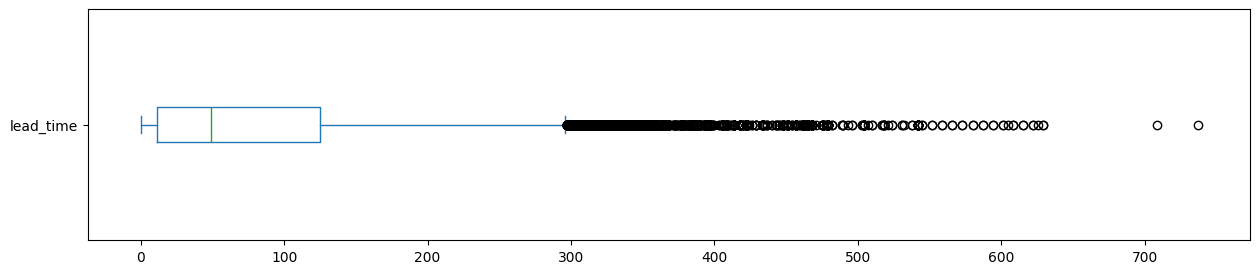

In [ ]:
df_num['lead_time'].plot.box(figsize=(15,3), vert=False);

In [ ]:
porcentaje_quantiles   = np.array([0,1,5,10,20,25,30,40,50,60,70,75,80,90,92.5,95,97.5,98,99,99.5,99.9,100])
datos_quantiles        = [(df_num['lead_time'].quantile(c) ,len(df_num['lead_time']) * c) for c in (porcentaje_quantiles / 100)]

pd.DataFrame(datos_quantiles,porcentaje_quantiles).transpose()

,0.000,1.000,5.000,10.000,20.000,25.000,30.000,40.000,50.000,60.000,...,80.000,90.000,92.500,95.000,97.500,98.000,99.000,99.500,99.900,100.000
0,0.000,0.000,0.000,1.000,7.000,11.000,17.000,31.000,49.000,73.000,...,148.000,204.000,224.000,256.000,304.000,315.000,347.000,386.000,479.000,737.000
1,0.000,874.090,4370.450,8740.900,17481.800,21852.250,26222.700,34963.600,43704.500,52445.400,...,69927.200,78668.100,80853.325,83038.550,85223.775,85660.820,86534.910,86971.955,87321.591,87409.000


In [ ]:
q1            = df_num['lead_time'].quantile(0.25)
print('cuantil 1 - 25% ', q1)
q2            = df_num['lead_time'].quantile(0.50)
print('\nmediana   - 50% ', q2)
q3            = df_num['lead_time'].quantile(0.75)
print('\ncuantil 3 - 75% ', q3)

IQR           = q3 - q1
print('\nrango intercuartil  IQR ', IQR)

min_threshold = q1 - 1.5 * IQR
max_threshold = q3 + 1.5 * IQR
print('\nvalor mínimo ',min_threshold)
print('valor máximo ',max_threshold)

cuantil 1 - 25%  11.0

mediana   - 50%  49.0

cuantil 3 - 75%  125.0

rango intercuartil  IQR  114.0

valor mínimo  -160.0
valor máximo  296.0


In [ ]:
tope_alto = round(np.percentile(df_num["lead_time"],99.9),2)
print(tope_alto)
df_num.loc[df_num["lead_time"]>tope_alto,"lead_time"] = tope_alto

479.0


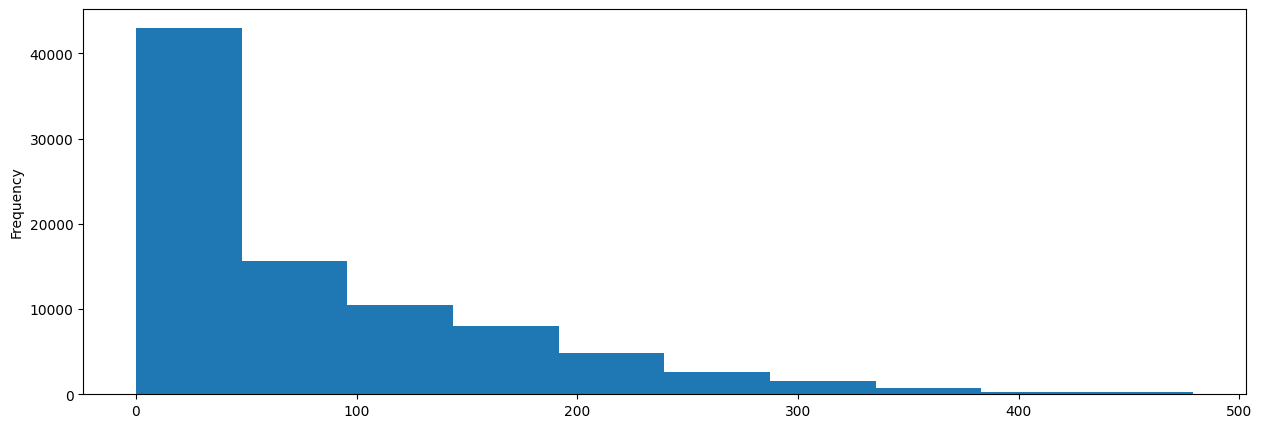

In [ ]:
df_num['lead_time'].plot.hist(figsize=(15,5));

#### 2) Analizamos la columna ADR

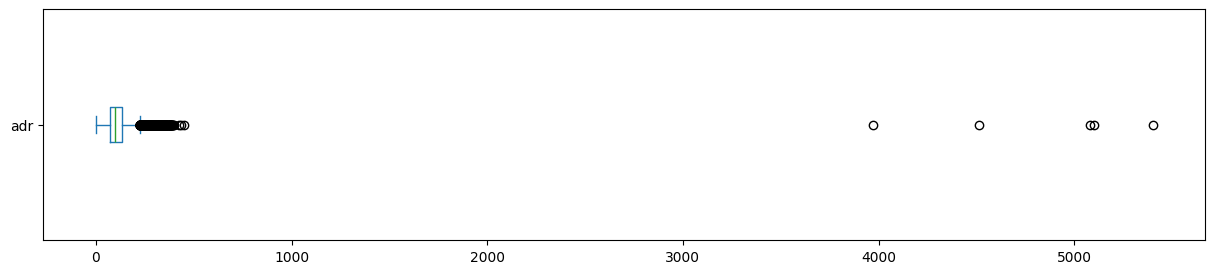

In [ ]:
df_num['adr'].plot.box(figsize=(15,3), vert=False);

In [ ]:
porcentaje_quantiles   = np.array([0,1,5,10,20,25,30,40,50,60,70,75,80,90,92.5,95,97.5,98,99,99.5,99.9,100])
datos_quantiles        = [(df_num['adr'].quantile(c) ,len(df_num['adr']) * c) for c in (porcentaje_quantiles / 100)]

pd.DataFrame(datos_quantiles,porcentaje_quantiles).transpose()

,0.000,1.000,5.000,10.000,20.000,25.000,30.000,40.000,50.000,60.000,...,80.000,90.000,92.500,95.000,97.500,98.000,99.000,99.500,99.900,100.000
0,0.000,0.000,36.860,48.000,65.000,72.000,77.230,88.400,98.100,110.160,...,144.000,174.000,188.000,204.000,230.000,239.000,261.394,285.000,335.000,5400.000
1,0.000,874.090,4370.450,8740.900,17481.800,21852.250,26222.700,34963.600,43704.500,52445.400,...,69927.200,78668.100,80853.325,83038.550,85223.775,85660.820,86534.910,86971.955,87321.591,87409.000


In [ ]:
q1            = df_num['adr'].quantile(0.25)
print('cuantil 1 - 25% ', q1)
q2            = df_num['adr'].quantile(0.50)
print('\nmediana   - 50% ', q2)
q3            = df_num['adr'].quantile(0.75)
print('\ncuantil 3 - 75% ', q3)

IQR           = q3 - q1
print('\nrango intercuartil  IQR ', IQR)

min_threshold = q1 - 1.5 * IQR
max_threshold = q3 + 1.5 * IQR
print('\nvalor mínimo ',min_threshold)
print('valor máximo ',max_threshold)

cuantil 1 - 25%  72.0

mediana   - 50%  98.1

cuantil 3 - 75%  134.0

rango intercuartil  IQR  62.0

valor mínimo  -21.0
valor máximo  227.0


In [ ]:
tope_alto = round(np.percentile(df_num["adr"],99.9),2)
print(tope_alto)
df_num.loc[df_num["adr"]>tope_alto,"adr"] = tope_alto

335.0


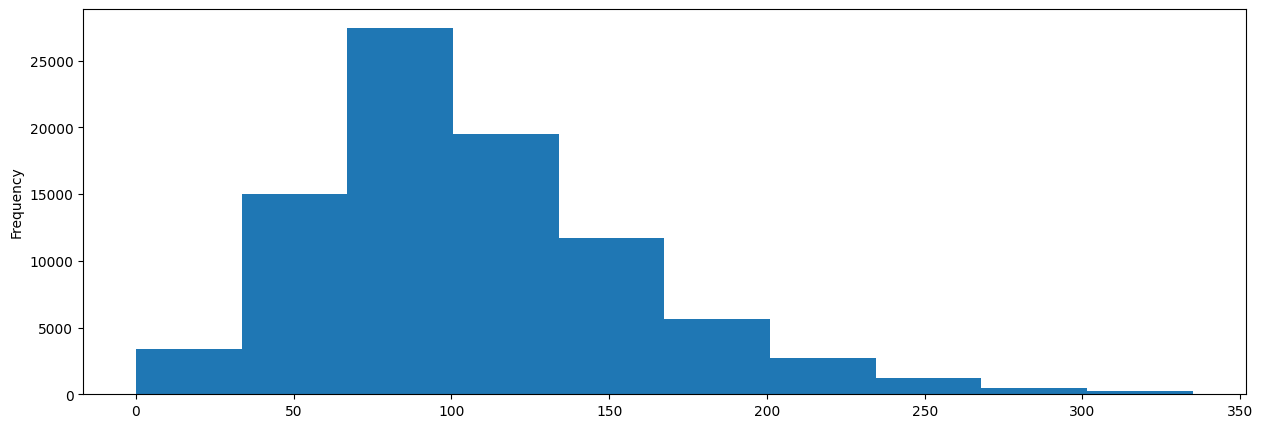

In [ ]:
df_num['adr'].plot.hist(figsize=(15,5));

#### 3) Analizamos la columna stays_in_week_nights

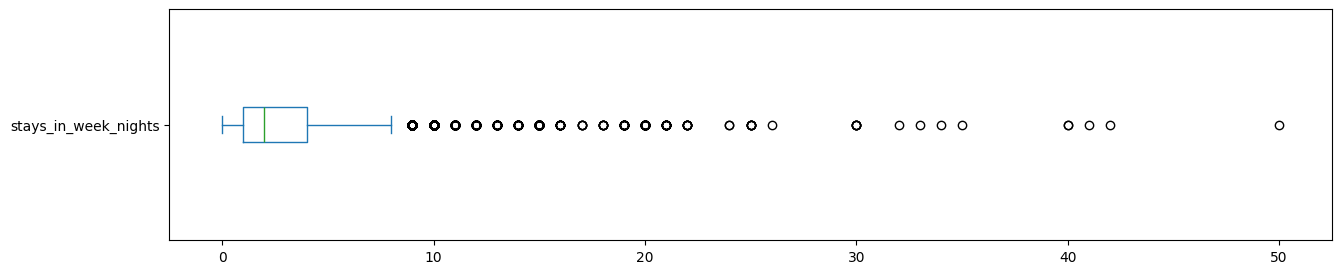

In [ ]:
df_num['stays_in_week_nights'].plot.box(figsize=(15,3), vert=False);

In [ ]:
porcentaje_quantiles   = np.array([0,10,25,50,75,80,90,92.5,95,97.5,98,99,99.5,99.9,99.95,99.96,99.97,99.98,99.99])
datos_quantiles        = [(df_num['stays_in_week_nights'].quantile(c) ,len(df_num['stays_in_week_nights']) * c) for c in (porcentaje_quantiles / 100)]

pd.DataFrame(datos_quantiles,porcentaje_quantiles).transpose()

,0.000,10.000,25.000,50.000,75.000,80.000,90.000,92.500,95.000,97.500,98.000,99.000,99.500,99.900,99.950,99.960,99.970,99.980,99.990
0,0.000,1.000,1.000,2.000,4.000,4.000,5.000,5.000,6.000,7.000,8.000,10.000,10.000,19.000,21.000,21.000,22.000,25.000,30.518
1,0.000,8740.900,21852.250,43704.500,65556.750,69927.200,78668.100,80853.325,83038.550,85223.775,85660.820,86534.910,86971.955,87321.591,87365.296,87374.036,87382.777,87391.518,87400.259


In [ ]:
q1            = df_num['stays_in_week_nights'].quantile(0.25)
print('cuantil 1 - 25% ', q1)
q2            = df_num['stays_in_week_nights'].quantile(0.50)
print('\nmediana   - 50% ', q2)
q3            = df_num['stays_in_week_nights'].quantile(0.75)
print('\ncuantil 3 - 75% ', q3)

IQR           = q3 - q1
print('\nrango intercuartil  IQR ', IQR)

min_threshold = q1 - 1.5 * IQR
max_threshold = q3 + 1.5 * IQR
print('\nvalor mínimo ',min_threshold)
print('valor máximo ',max_threshold)

cuantil 1 - 25%  1.0

mediana   - 50%  2.0

cuantil 3 - 75%  4.0

rango intercuartil  IQR  3.0

valor mínimo  -3.5
valor máximo  8.5


In [ ]:
tope_alto = round(np.percentile(df_num["stays_in_week_nights"],99.97),2)
print(tope_alto)
df_num.loc[df_num["stays_in_week_nights"]>tope_alto,"stays_in_week_nights"] = tope_alto

22.0


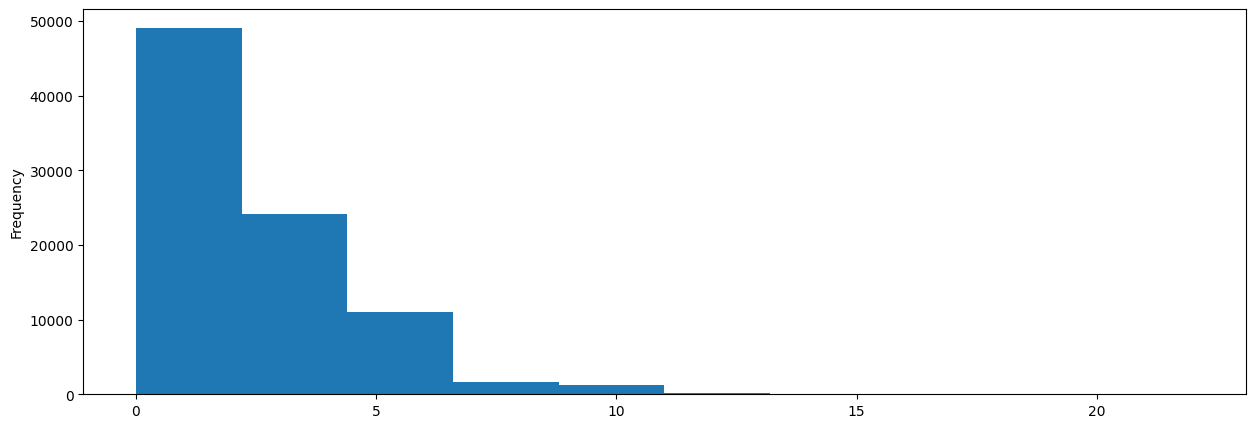

In [ ]:
df_num['stays_in_week_nights'].plot.hist(figsize=(15,5));

#### 4) Analizamos la columna days_in_waiting_list

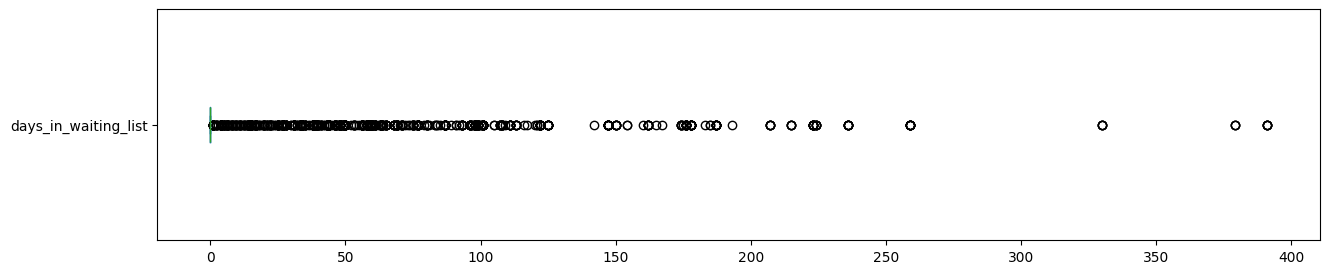

In [ ]:
df_num['days_in_waiting_list'].plot.box(figsize=(15,3), vert=False);

In [ ]:
porcentaje_quantiles   = np.array([0,10,25,50,75,80,90,92.5,95,97.5,98,99,99.5,99.70,99.80,99.85,99.86,99.87,99.89,99.9])
datos_quantiles        = [(df_num['days_in_waiting_list'].quantile(c) ,len(df_num['days_in_waiting_list']) * c) for c in (porcentaje_quantiles / 100)]

pd.DataFrame(datos_quantiles,porcentaje_quantiles).transpose()

,0.000,10.000,25.000,50.000,75.000,80.000,90.000,92.500,95.000,97.500,98.000,99.000,99.500,99.700,99.800,99.850,99.860,99.870,99.890,99.900
0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,59.000,87.000,111.000,125.000,147.000,147.000,164.554,176.000
1,0.000,8740.900,21852.250,43704.500,65556.750,69927.200,78668.100,80853.325,83038.550,85223.775,85660.820,86534.910,86971.955,87146.773,87234.182,87277.886,87286.627,87295.368,87312.850,87321.591


In [ ]:
q1            = df_num['days_in_waiting_list'].quantile(0.25)
print('cuantil 1 - 25% ', q1)
q2            = df_num['days_in_waiting_list'].quantile(0.50)
print('\nmediana   - 50% ', q2)
q3            = df_num['days_in_waiting_list'].quantile(0.75)
print('\ncuantil 3 - 75% ', q3)

IQR           = q3 - q1
print('\nrango intercuartil  IQR ', IQR)

min_threshold = q1 - 1.5 * IQR
max_threshold = q3 + 1.5 * IQR
print('\nvalor mínimo ',min_threshold)
print('valor máximo ',max_threshold)

cuantil 1 - 25%  0.0

mediana   - 50%  0.0

cuantil 3 - 75%  0.0

rango intercuartil  IQR  0.0

valor mínimo  0.0
valor máximo  0.0


In [ ]:
tope_alto = round(np.percentile(df_num["days_in_waiting_list"],99.85),2)
print(tope_alto)
df_num.loc[df_num["days_in_waiting_list"]>tope_alto,"days_in_waiting_list"] = tope_alto

125.0


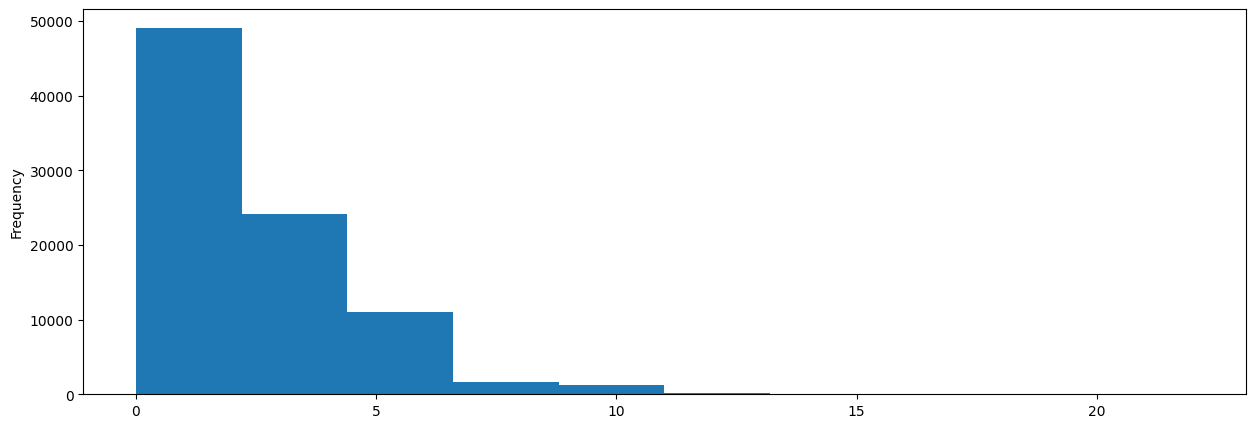

In [ ]:
df_num['stays_in_week_nights'].plot.hist(figsize=(15,5));

## Grabación del fin de fase

In [ ]:
df_cat

,hotel,is_canceled,arrival_date_year,arrival_date_month,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
0,Resort Hotel,0,2015.000,July,BB,PRT,Direct,Direct,0.000,C,C,No Deposit,Transient,Check-Out,2015-01-07
1,Resort Hotel,0,2015.000,July,BB,PRT,Direct,Direct,0.000,C,C,No Deposit,Transient,Check-Out,2015-01-07
3,Resort Hotel,0,2015.000,July,BB,GBR,Corporate,Corporate,0.000,A,A,No Deposit,Transient,Check-Out,2015-02-07
4,Resort Hotel,0,2015.000,July,BB,GBR,Online TA,TA/TO,0.000,A,A,No Deposit,Transient,Check-Out,2015-03-07
6,Resort Hotel,0,2015.000,July,BB,PRT,Direct,Direct,0.000,C,C,No Deposit,Transient,Check-Out,2015-03-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,2017.000,August,BB,BEL,Offline TA/TO,TA/TO,0.000,A,A,No Deposit,Transient,Check-Out,2017-06-09
119386,City Hotel,0,2017.000,August,BB,FRA,Online TA,TA/TO,0.000,E,E,No Deposit,Transient,Check-Out,2017-07-09
119387,City Hotel,0,2017.000,August,BB,DEU,Online TA,TA/TO,0.000,D,D,No Deposit,Transient,Check-Out,2017-07-09
119388,City Hotel,0,2017.000,August,BB,GBR,Online TA,TA/TO,0.000,A,A,No Deposit,Transient,Check-Out,2017-07-09


In [ ]:
df_cat.isna().sum().sort_values(ascending=False)

,0
hotel,0
is_canceled,0
arrival_date_year,0
arrival_date_month,0
meal,0
country,0
market_segment,0
distribution_channel,0
is_repeated_guest,0
reserved_room_type,0


In [ ]:
df_num.isna().sum().sort_values(ascending=False)

,0
lead_time,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0
children,0
babies,0
previous_cancellations,0
previous_bookings_not_canceled,0


In [ ]:
#df_cat.to_pickle(str(ARTIFACTS_DIR / 'df_categoricos_fin_quality_cleaning.pickle'))
#df_num.to_pickle(str(ARTIFACTS_DIR / 'df_numericos_fin_quality_cleaning.pickle'))

# EDA

## Carga de Librerías

In [ ]:
#EDA
import scipy as scipy
import seaborn as sns

%matplotlib inline

#Automcompletar rápido
%config IPCompleter.greedy=True
#Desactivar la notación científica
pd.options.display.float_format = '{:.3f}'.format

## Anáisis Univariado

### Categóricas

#### Conteo

In [ ]:
# Conteo si una reserva fue cancelada o no
df_cat['is_canceled'].value_counts()

,count
is_canceled,
0,63376
1,24033


In [ ]:
# Conteo si un cliente es recurrente o no
df_cat['is_repeated_guest'].value_counts()

,count
is_repeated_guest,
0.000,83989
1.000,3420


In [ ]:
# Conteo del tipo de comida solicitada
df_cat['meal'].value_counts()

,count
meal,
BB,67968
SC,9481
HB,9086
Undefined,514
FB,360


In [ ]:
# Conteo del tipo de cliente
df_cat['customer_type'].value_counts()

,count
customer_type,
Transient,71986
Transient-Party,11738
Contract,3141
Group,544


In [ ]:
# Conteo del estado de la reserva
df_cat['reservation_status'].value_counts()

,count
reservation_status,
Check-Out,63372
Canceled,23023
No-Show,1014


#### Proporciones

In [ ]:
# Explorar la proporción de reservas canceladas y no canceladas
df_cat['is_canceled'].value_counts(normalize=True)

,proportion
is_canceled,
0,0.725
1,0.275


In [ ]:
# Explorar la proporción de huéspedes recurrentes frente a huéspedes nuevos
df_cat['is_repeated_guest'].value_counts(normalize=True)

,proportion
is_repeated_guest,
0.000,0.961
1.000,0.039


In [ ]:
# Explorar la proporción de cada tipo de cliente
df_cat['customer_type'].value_counts(normalize=True)

,proportion
customer_type,
Transient,0.824
Transient-Party,0.134
Contract,0.036
Group,0.006


In [ ]:
# Explorar la proporción de reservas en cada tipo de hotel
df_cat['hotel'].value_counts(normalize=True)

,proportion
hotel,
City Hotel,0.611
Resort Hotel,0.389


#### Moda

In [ ]:
df_cat.mode()

,hotel,is_canceled,arrival_date_year,arrival_date_month,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
0,City Hotel,0,2016.000,August,BB,PRT,Online TA,TA/TO,0.000,A,A,No Deposit,Transient,Check-Out,2016-02-14


#### Gráfico de barras

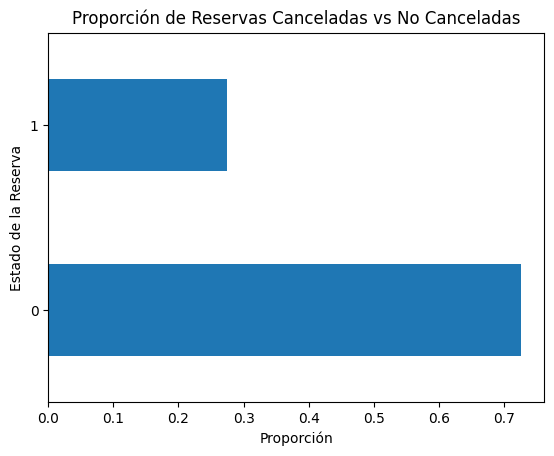

In [ ]:
df_cat['is_canceled'].value_counts(normalize=True).plot.barh()
plt.title('Proporción de Reservas Canceladas vs No Canceladas')
plt.xlabel('Proporción')
plt.ylabel('Estado de la Reserva')
plt.show()

Text(0, 0.5, 'Estado del Huésped')

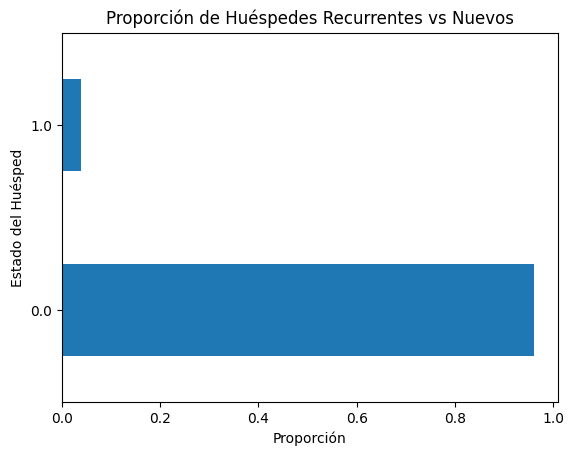

In [ ]:
df_cat['is_repeated_guest'].value_counts(normalize=True).plot.barh()
plt.title('Proporción de Huéspedes Recurrentes vs Nuevos')
plt.xlabel('Proporción')
plt.ylabel('Estado del Huésped')

<Axes: ylabel='customer_type'>

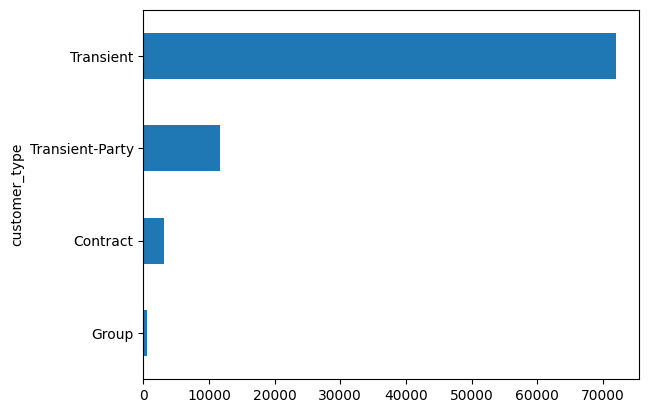

In [ ]:
df_cat['customer_type'].value_counts(ascending=True).plot.barh()

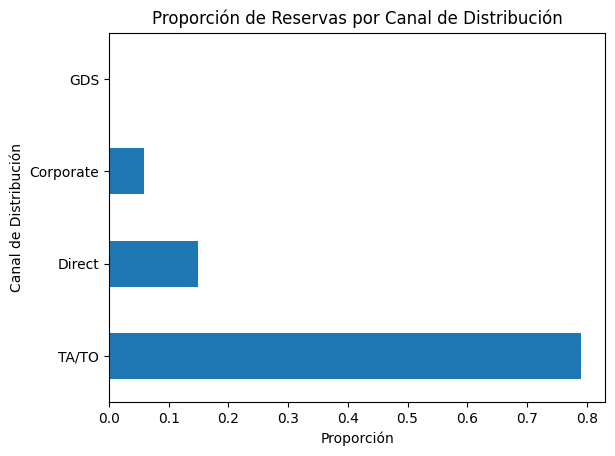

In [ ]:
df_cat['distribution_channel'].value_counts(normalize=True).plot.barh()
plt.title('Proporción de Reservas por Canal de Distribución')
plt.xlabel('Proporción')
plt.ylabel('Canal de Distribución')
plt.show()

### Numéricas

#### Media o Promedio (T.Central)

In [ ]:
df_num['lead_time'].mean()

np.float64(79.8615131164983)

In [ ]:
df_num['adr'].mean()

np.float64(106.25319612396892)

#### Mediana (T.Central)

In [ ]:
df_num['lead_time'].median()

49.0

In [ ]:
df_num['adr'].median()

98.1

In [ ]:
df_num['arrival_date_week_number'].median()

27.0

#### Estadísticos básicos (Dispersión)

In [ ]:
df_num_statistic = df_num.describe().T

In [ ]:
df_num_statistic

,count,mean,std,min,25%,50%,75%,max
lead_time,87409.000,79.862,85.728,0.000,11.000,49.000,125.000,479.000
arrival_date_week_number,87409.000,26.838,13.674,1.000,16.000,27.000,37.000,53.000
arrival_date_day_of_month,87409.000,15.816,8.835,1.000,8.000,16.000,23.000,31.000
stays_in_weekend_nights,87409.000,1.005,1.032,0.000,0.000,1.000,2.000,19.000
stays_in_week_nights,87409.000,2.623,2.021,0.000,1.000,2.000,4.000,22.000
adults,87409.000,1.876,0.626,0.000,2.000,2.000,2.000,55.000
children,87409.000,0.139,0.456,0.000,0.000,0.000,0.000,10.000
babies,87409.000,0.011,0.114,0.000,0.000,0.000,0.000,10.000
previous_cancellations,87409.000,0.030,0.369,0.000,0.000,0.000,0.000,26.000
previous_bookings_not_canceled,87409.000,0.184,1.732,0.000,0.000,0.000,0.000,72.000


In [ ]:
df_num_statistic['rango'] = df_num_statistic.loc[:,'max'] - df_num_statistic.loc[:,'min']
df_num_statistic

,count,mean,std,min,25%,50%,75%,max,rango
lead_time,87409.000,79.862,85.728,0.000,11.000,49.000,125.000,479.000,479.000
arrival_date_week_number,87409.000,26.838,13.674,1.000,16.000,27.000,37.000,53.000,52.000
arrival_date_day_of_month,87409.000,15.816,8.835,1.000,8.000,16.000,23.000,31.000,30.000
stays_in_weekend_nights,87409.000,1.005,1.032,0.000,0.000,1.000,2.000,19.000,19.000
stays_in_week_nights,87409.000,2.623,2.021,0.000,1.000,2.000,4.000,22.000,22.000
adults,87409.000,1.876,0.626,0.000,2.000,2.000,2.000,55.000,55.000
children,87409.000,0.139,0.456,0.000,0.000,0.000,0.000,10.000,10.000
babies,87409.000,0.011,0.114,0.000,0.000,0.000,0.000,10.000,10.000
previous_cancellations,87409.000,0.030,0.369,0.000,0.000,0.000,0.000,26.000,26.000
previous_bookings_not_canceled,87409.000,0.184,1.732,0.000,0.000,0.000,0.000,72.000,72.000


In [ ]:
df_num_statistic['rango_IQR'] = df_num_statistic.loc[:,'75%'] - df_num_statistic.loc[:,'25%'] # AGREGAMOS LA COLUMNA rango_IQR
df_num_statistic

,count,mean,std,min,25%,50%,75%,max,rango,rango_IQR
lead_time,87409.000,79.862,85.728,0.000,11.000,49.000,125.000,479.000,479.000,114.000
arrival_date_week_number,87409.000,26.838,13.674,1.000,16.000,27.000,37.000,53.000,52.000,21.000
arrival_date_day_of_month,87409.000,15.816,8.835,1.000,8.000,16.000,23.000,31.000,30.000,15.000
stays_in_weekend_nights,87409.000,1.005,1.032,0.000,0.000,1.000,2.000,19.000,19.000,2.000
stays_in_week_nights,87409.000,2.623,2.021,0.000,1.000,2.000,4.000,22.000,22.000,3.000
adults,87409.000,1.876,0.626,0.000,2.000,2.000,2.000,55.000,55.000,0.000
children,87409.000,0.139,0.456,0.000,0.000,0.000,0.000,10.000,10.000,0.000
babies,87409.000,0.011,0.114,0.000,0.000,0.000,0.000,10.000,10.000,0.000
previous_cancellations,87409.000,0.030,0.369,0.000,0.000,0.000,0.000,26.000,26.000,0.000
previous_bookings_not_canceled,87409.000,0.184,1.732,0.000,0.000,0.000,0.000,72.000,72.000,0.000


In [ ]:
df_num_statistic['min_outlier'] = df_num_statistic.loc[:,'25%'] - 1.5 * df_num_statistic.loc[:,'75%'] - df_num_statistic.loc[:,'25%']
df_num_statistic['max_outlier'] = df_num_statistic.loc[:,'75%'] + 1.5 * df_num_statistic.loc[:,'75%'] - df_num_statistic.loc[:,'25%']
df_num_statistic

,count,mean,std,min,25%,50%,75%,max,rango,rango_IQR,min_outlier,max_outlier
lead_time,87409.000,79.862,85.728,0.000,11.000,49.000,125.000,479.000,479.000,114.000,-187.500,301.500
arrival_date_week_number,87409.000,26.838,13.674,1.000,16.000,27.000,37.000,53.000,52.000,21.000,-55.500,76.500
arrival_date_day_of_month,87409.000,15.816,8.835,1.000,8.000,16.000,23.000,31.000,30.000,15.000,-34.500,49.500
stays_in_weekend_nights,87409.000,1.005,1.032,0.000,0.000,1.000,2.000,19.000,19.000,2.000,-3.000,5.000
stays_in_week_nights,87409.000,2.623,2.021,0.000,1.000,2.000,4.000,22.000,22.000,3.000,-6.000,9.000
adults,87409.000,1.876,0.626,0.000,2.000,2.000,2.000,55.000,55.000,0.000,-3.000,3.000
children,87409.000,0.139,0.456,0.000,0.000,0.000,0.000,10.000,10.000,0.000,0.000,0.000
babies,87409.000,0.011,0.114,0.000,0.000,0.000,0.000,10.000,10.000,0.000,0.000,0.000
previous_cancellations,87409.000,0.030,0.369,0.000,0.000,0.000,0.000,26.000,26.000,0.000,0.000,0.000
previous_bookings_not_canceled,87409.000,0.184,1.732,0.000,0.000,0.000,0.000,72.000,72.000,0.000,0.000,0.000


#### BoxPlot

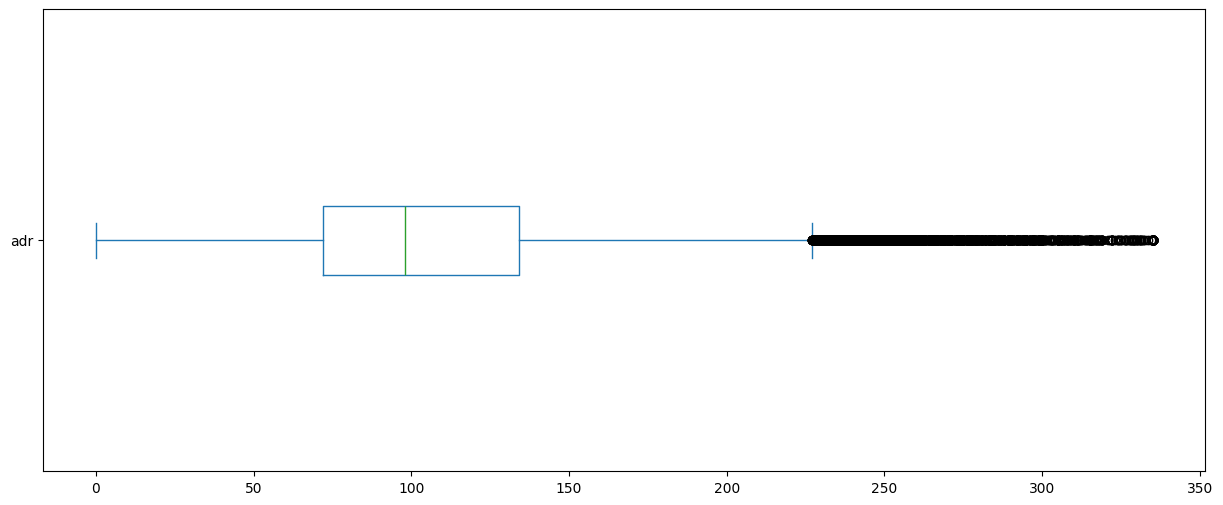

In [ ]:
df_num['adr'].plot.box(figsize = (15,6), vert=False);

#### Histogramas

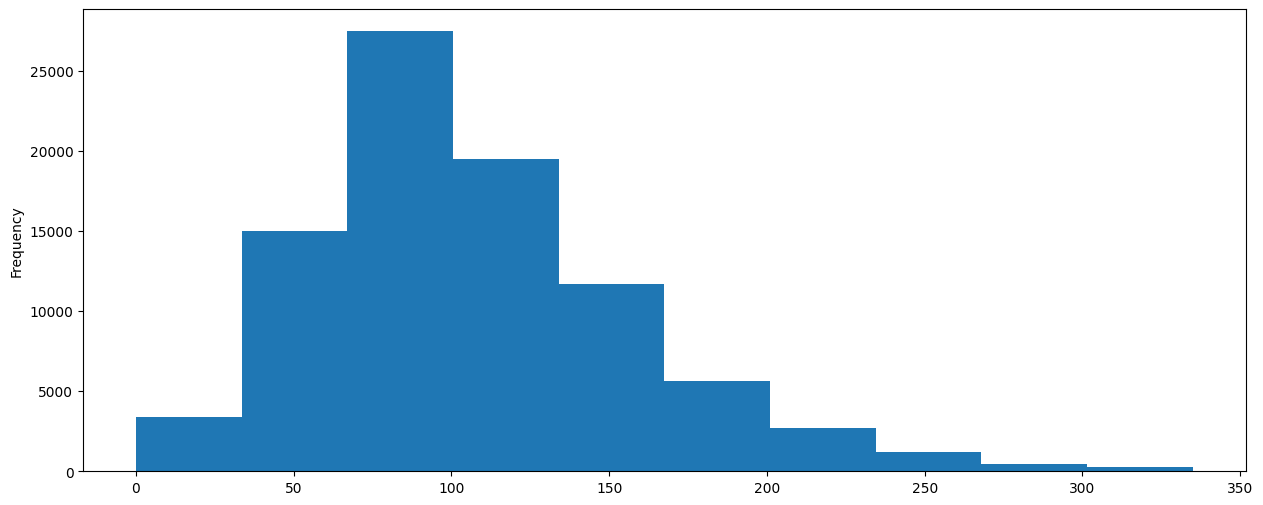

In [ ]:
df_num['adr'].plot.hist(figsize = (15,6));

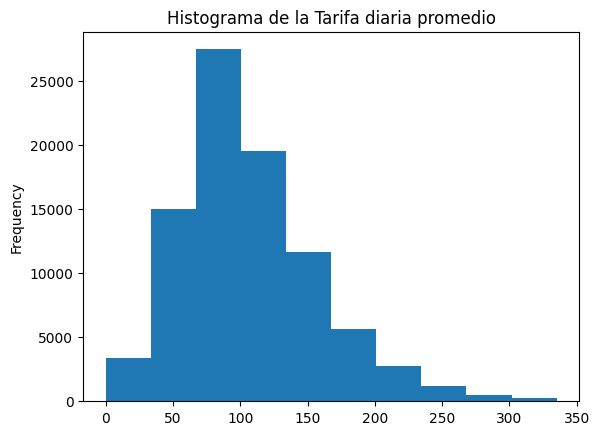

In [ ]:
df_num['adr'].plot.hist()
plt.title('Histograma de la Tarifa diaria promedio');

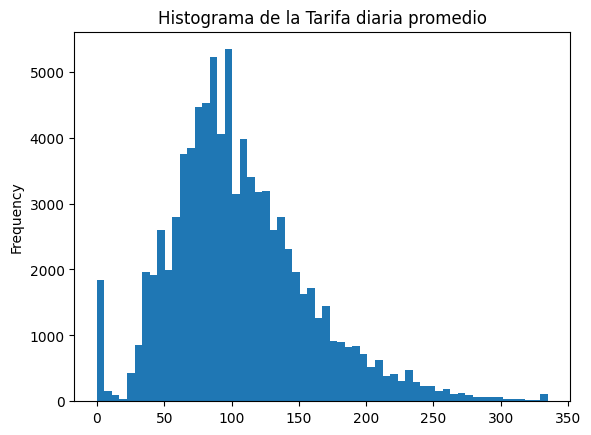

In [ ]:
df_num['adr'].plot.hist(bins = 60)
plt.title('Histograma de la Tarifa diaria promedio');

#### Función de probabilidad de masa

In [ ]:
df_num['stays_in_week_nights'].value_counts().sort_index()

,count
stays_in_week_nights,
0.000,6175
1.000,22191
2.000,20751
3.000,16265
4.000,7874
5.000,9663
6.000,1379
7.000,967
8.000,613


In [ ]:
len(df_num['stays_in_week_nights'])

87409

In [ ]:
df_pmf = df_num['stays_in_week_nights'].value_counts().sort_index() / len(df_num['stays_in_week_nights'])
df_pmf

,count
stays_in_week_nights,
0.000,0.071
1.000,0.254
2.000,0.237
3.000,0.186
4.000,0.090
5.000,0.111
6.000,0.016
7.000,0.011
8.000,0.007


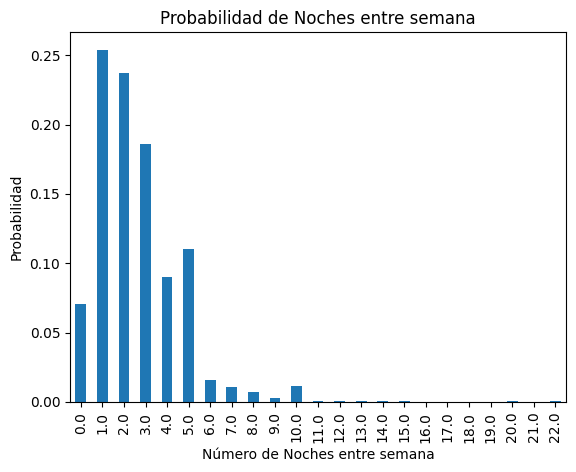

In [ ]:
df_pmf.plot(kind='bar')
plt.xlabel("Número de Noches entre semana")
plt.ylabel("Probabilidad")
plt.title("Probabilidad de Noches entre semana")
plt.show()



```
# Esto tiene formato de código
```

#### Función de distribución acumulada

In [ ]:
pmf = df_num['lead_time'].value_counts().sort_index() / len(df_num['lead_time'])
pmf

,count
lead_time,
0.000,0.068
1.000,0.037
2.000,0.022
3.000,0.019
4.000,0.018
...,...
471.000,0.000
475.000,0.000
476.000,0.000


In [ ]:
pmf.cumsum()

,count
lead_time,
0.000,0.068
1.000,0.105
2.000,0.127
3.000,0.147
4.000,0.165
...,...
471.000,0.999
475.000,0.999
476.000,0.999


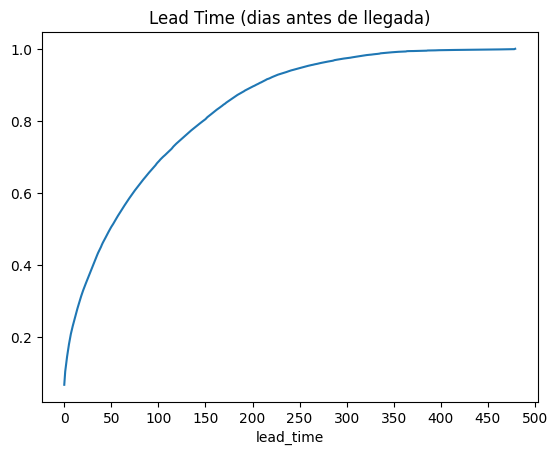

In [ ]:
pmf.cumsum().plot()
plt.locator_params(axis='x', nbins=20) #20
plt.title('Lead Time (dias antes de llegada)');

### Análisis Bivariado (Unión de DF Num AND Category)

#### Unión de los dataframes

In [ ]:
df_cat_num = pd.concat([df_cat,df_num], axis =1 )
df_cat_num

,hotel,is_canceled,arrival_date_year,arrival_date_month,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,...,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,0,2015.000,July,BB,PRT,Direct,Direct,0.000,C,...,2.000,0.000,0.000,0.000,0.000,3.000,0,0.000,0.000,0.000
1,Resort Hotel,0,2015.000,July,BB,PRT,Direct,Direct,0.000,C,...,2.000,0.000,0.000,0.000,0.000,4.000,0,0.000,0.000,0.000
3,Resort Hotel,0,2015.000,July,BB,GBR,Corporate,Corporate,0.000,A,...,1.000,0.000,0.000,0.000,0.000,0.000,0,75.000,0.000,0.000
4,Resort Hotel,0,2015.000,July,BB,GBR,Online TA,TA/TO,0.000,A,...,2.000,0.000,0.000,0.000,0.000,0.000,0,98.000,0.000,1.000
6,Resort Hotel,0,2015.000,July,BB,PRT,Direct,Direct,0.000,C,...,2.000,0.000,0.000,0.000,0.000,0.000,0,107.000,0.000,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,2017.000,August,BB,BEL,Offline TA/TO,TA/TO,0.000,A,...,2.000,0.000,0.000,0.000,0.000,0.000,0,96.140,0.000,0.000
119386,City Hotel,0,2017.000,August,BB,FRA,Online TA,TA/TO,0.000,E,...,3.000,0.000,0.000,0.000,0.000,0.000,0,225.430,0.000,2.000
119387,City Hotel,0,2017.000,August,BB,DEU,Online TA,TA/TO,0.000,D,...,2.000,0.000,0.000,0.000,0.000,0.000,0,157.710,0.000,4.000
119388,City Hotel,0,2017.000,August,BB,GBR,Online TA,TA/TO,0.000,A,...,2.000,0.000,0.000,0.000,0.000,0.000,0,104.400,0.000,0.000


#### Numérico vs Numéricos

##### Scatter

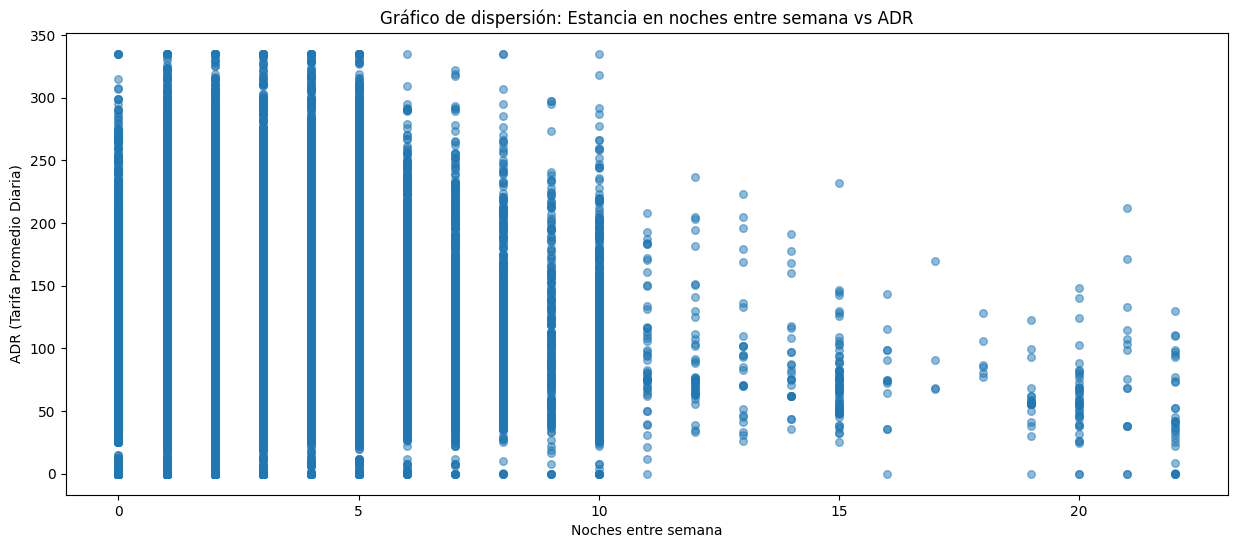

In [ ]:
f, ax = plt.subplots(figsize=(15,6))
ax.scatter(df_cat_num['stays_in_week_nights'], df_cat_num['adr'], alpha=0.5, s=30)
ax.set_title('Gráfico de dispersión: Estancia en noches entre semana vs ADR')
ax.set_xlabel('Noches entre semana')
ax.set_ylabel('ADR (Tarifa Promedio Diaria)')
plt.show()

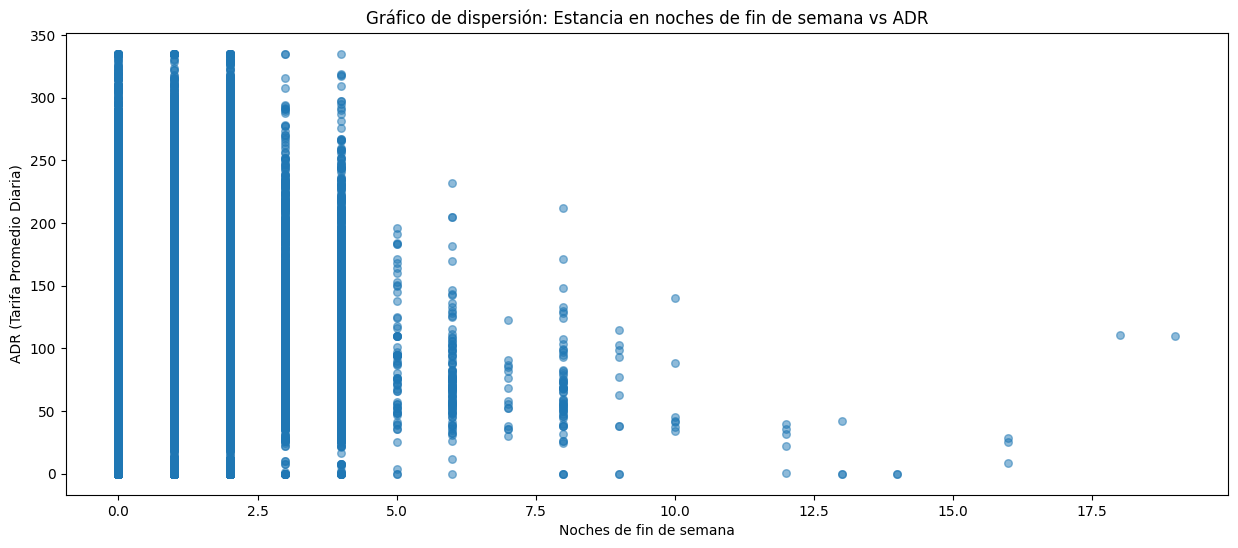

In [ ]:
f, ax = plt.subplots(figsize=(15,6))
ax.scatter(df_cat_num['stays_in_weekend_nights'], df_cat_num['adr'], alpha=0.5, s=30)
ax.set_title('Gráfico de dispersión: Estancia en noches de fin de semana vs ADR')
ax.set_xlabel('Noches de fin de semana')
ax.set_ylabel('ADR (Tarifa Promedio Diaria)')
plt.show()

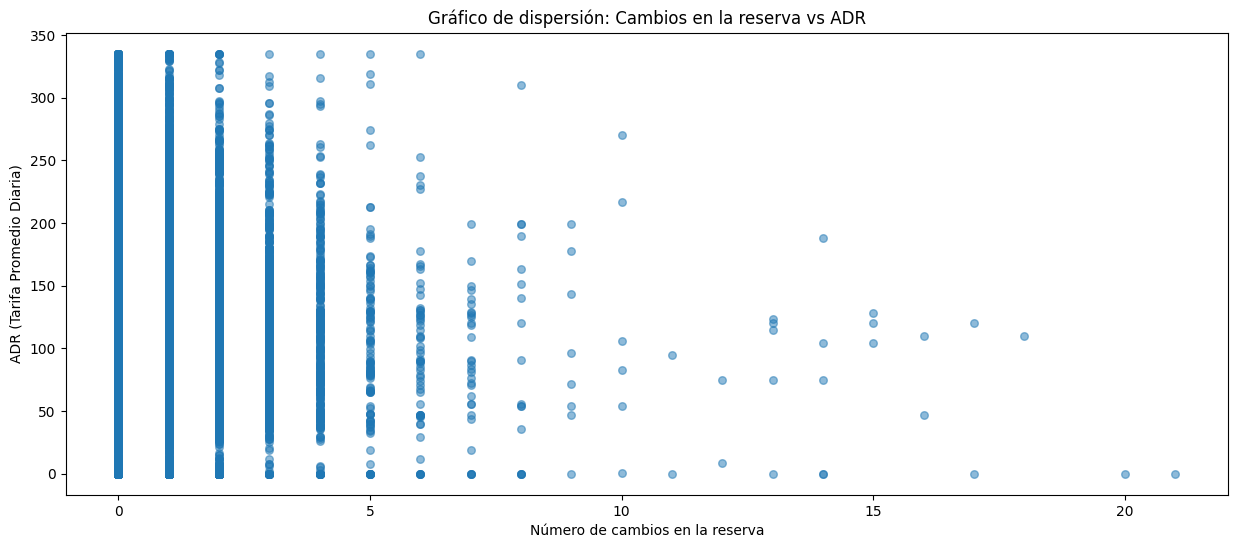

In [ ]:
f, ax = plt.subplots(figsize=(15,6))
ax.scatter(df_cat_num['booking_changes'], df_cat_num['adr'], alpha=0.5, s=30)
ax.set_title('Gráfico de dispersión: Cambios en la reserva vs ADR')
ax.set_xlabel('Número de cambios en la reserva')
ax.set_ylabel('ADR (Tarifa Promedio Diaria)')
plt.show()

##### Histograma 2D

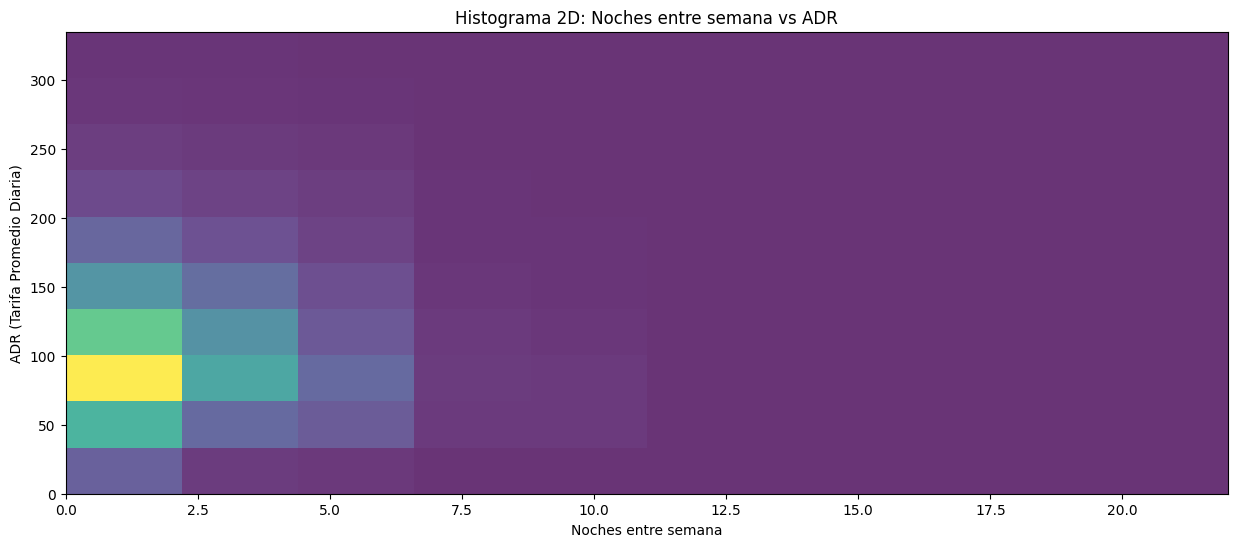

In [ ]:
f, ax = plt.subplots(figsize=(15,6))
ax.hist2d(data=df_num, x = 'stays_in_week_nights', y ='adr', alpha=0.8)
ax.set_title('Histograma 2D: Noches entre semana vs ADR')
ax.set_xlabel('Noches entre semana')
ax.set_ylabel('ADR (Tarifa Promedio Diaria)')
plt.show()

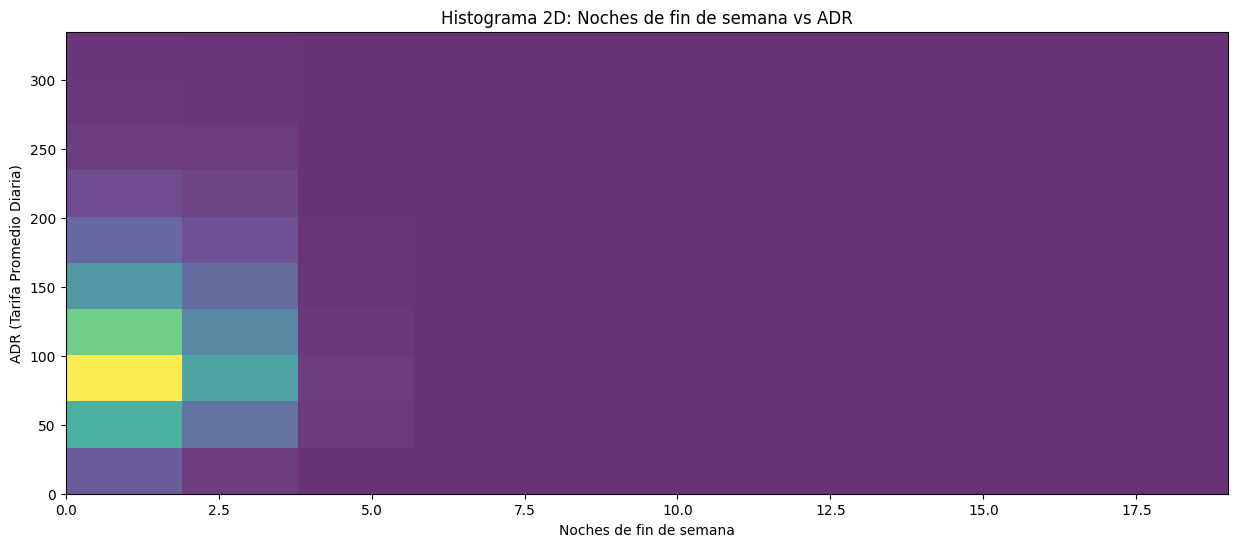

In [ ]:
f, ax = plt.subplots(figsize=(15,6))
ax.hist2d(data=df_num, x = 'stays_in_weekend_nights', y ='adr', alpha=0.8)
ax.set_title('Histograma 2D: Noches de fin de semana vs ADR')
ax.set_xlabel('Noches de fin de semana')
ax.set_ylabel('ADR (Tarifa Promedio Diaria)')
plt.show()

##### Scatter y distribución

In [ ]:
sns.displot(
    data = df_num,
    x = 'lead_time',
    y = 'adr',
    rug = True,
    kind = 'kde'
);

In [ ]:
sns.displot(
    data = df_num,
    x = 'adults',
    y = 'adr',
    rug = True,
    kind = 'kde'
);

#### Gráficos de Categóricas vs Numéricas

###### Scatterplot

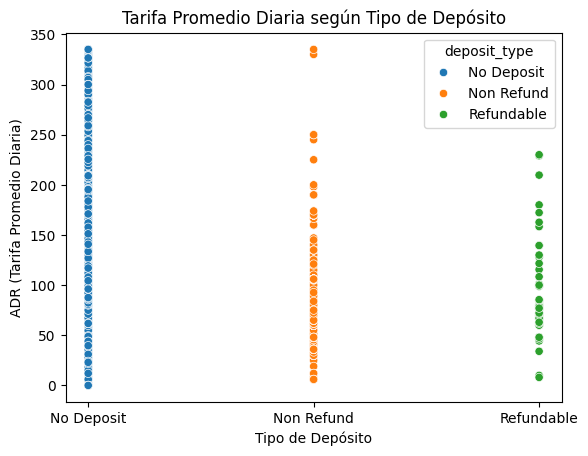

In [ ]:
sns.scatterplot(
    data=df_cat_num,
    x='deposit_type',
    y='adr',
    hue='deposit_type'
)
plt.title('Tarifa Promedio Diaria según Tipo de Depósito')
plt.xlabel('Tipo de Depósito')
plt.ylabel('ADR (Tarifa Promedio Diaria)')
plt.show()

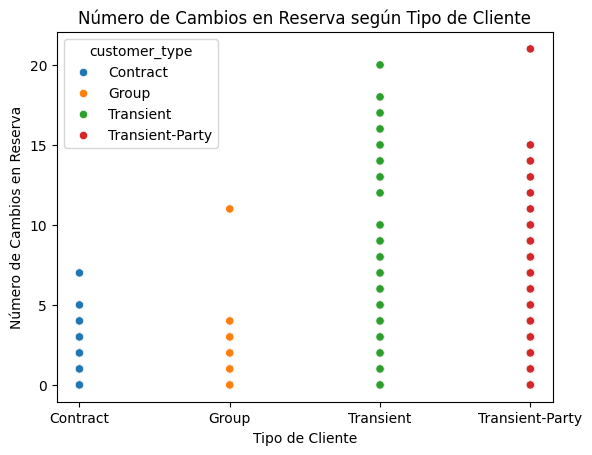

In [ ]:
sns.scatterplot(
    data=df_cat_num,
    x='customer_type',
    y='booking_changes',
    hue='customer_type'
)
plt.title('Número de Cambios en Reserva según Tipo de Cliente')
plt.xlabel('Tipo de Cliente')
plt.ylabel('Número de Cambios en Reserva')
plt.show()

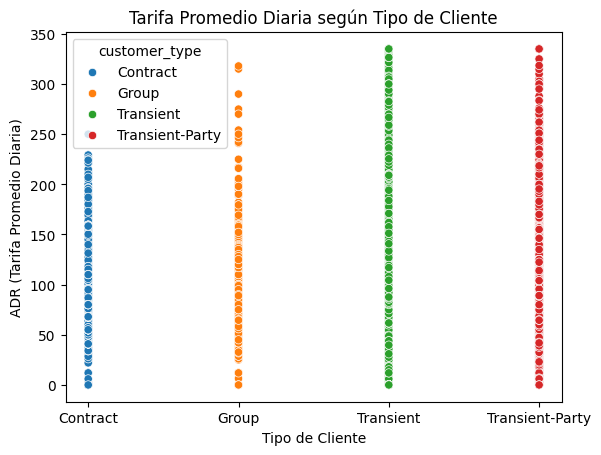

In [ ]:
sns.scatterplot(
    data=df_cat_num,
    x='customer_type',
    y='adr',
    hue='customer_type'
)

plt.title('Tarifa Promedio Diaria según Tipo de Cliente')
plt.xlabel('Tipo de Cliente')
plt.ylabel('ADR (Tarifa Promedio Diaria)')
plt.show()

###### Stripplot

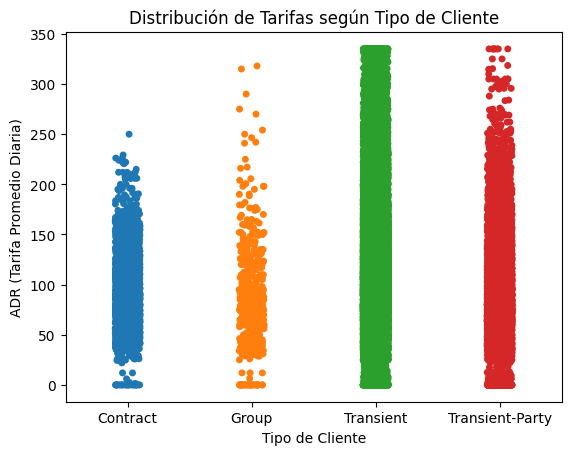

In [ ]:
sns.stripplot(
    data=df_cat_num,
    x='customer_type',
    y='adr',
    hue='customer_type'
)
plt.title('Distribución de Tarifas según Tipo de Cliente')
plt.xlabel('Tipo de Cliente')
plt.ylabel('ADR (Tarifa Promedio Diaria)')
plt.show()

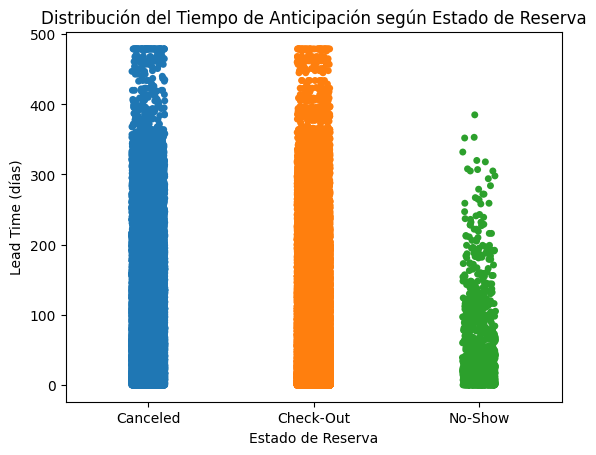

In [ ]:
sns.stripplot(
    data=df_cat_num,
    x='reservation_status',
    y='lead_time',
    hue='reservation_status'
)
plt.title('Distribución del Tiempo de Anticipación según Estado de Reserva')
plt.xlabel('Estado de Reserva')
plt.ylabel('Lead Time (días)')
plt.show()

###### Boxplot

In [ ]:
fig, ax = plt.subplots(figsize=(15,6))
sns.boxplot(
    data=df_cat_num,
    x='hotel',
    y='adr',
    hue='hotel',
    ax=ax
)
plt.title('Distribución de Tarifas según Tipo de Hotel')
plt.xlabel('Tipo de Hotel')
plt.ylabel('ADR (Tarifa Promedio Diaria)')
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(15,6))
sns.boxplot(
    data=df_cat_num,
    x='customer_type',
    y='adr',
    hue='customer_type',
    ax=ax
)
plt.title('Distribución de Tarifas según Tipo de Cliente')
plt.xlabel('Tipo de Cliente')
plt.ylabel('ADR (Tarifa Promedio Diaria)')
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(15,6))
sns.boxplot(
    data=df_cat_num,
    x='deposit_type',
    y='adr',
    hue='deposit_type',
    ax=ax
)
plt.title('Distribución de Tarifas según Tipo de Depósito')
plt.xlabel('Tipo de Depósito')
plt.ylabel('ADR (Tarifa Promedio Diaria)')
plt.show()

In [ ]:
plt.figure(figsize=(15,6))
sns.boxplot(
    data=df_cat_num,
    x='deposit_type',
    y='adr',
    hue='hotel'
)
plt.title('Distribución de Tarifas según Tipo de Depósito y Tipo de Hotel')
plt.xlabel('Tipo de Depósito')
plt.ylabel('ADR (Tarifa Promedio Diaria)')
plt.legend(title='Tipo de Hotel')
plt.show()

###### Grafico de Violin

In [ ]:
fig, ax = plt.subplots(figsize=(15,6))
sns.violinplot(
    data=df_cat_num,
    x='customer_type',
    y='adr',
    hue='customer_type',
    ax=ax
)
plt.title('Distribución de Tarifas según Tipo de Cliente')
plt.xlabel('Tipo de Cliente')
plt.ylabel('ADR (Tarifa Promedio Diaria)')
plt.show()

#### Correlación

##### diagrama de scatter

Scatter: lead_time vs adr

In [ ]:
f, ax = plt.subplots(figsize=(15, 6))
ax.scatter(data=df_num, x='lead_time', y='adr', alpha=0.5, s=30)
ax.set_title('Gráfico de dispersión lead_time vs adr')
ax.set_xlabel('lead_time')
ax.set_ylabel('adr')

Scatter: dispersión lead_time vs adr

In [ ]:
f, ax = plt.subplots(figsize=(15, 6))
mask = df_num['lead_time'].notna() & df_num['arrival_date_week_number'].notna()
ax.scatter(x=df_num.loc[mask, 'lead_time'], y=df_num.loc[mask, 'arrival_date_week_number'], alpha=0.5, s=30)
ax.set_title('Gráfico de dispersión lead_time vs arrival_date_week_number')
ax.set_xlabel('lead_time')
ax.set_ylabel('arrival_date_week_number')


##### Matriz de correlación

In [ ]:
df_num.corr()

##### Mapa de calor y Matriz de correlación

In [ ]:
fig, ax = plt.subplots(figsize=(15, 12))

sns.heatmap(
    data=df_num.corr(),
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.7,
    cmap=sns.diverging_palette(230, 20, as_cmap=True),
    annot=True,
    fmt='.2f',
    square=True,
    annot_kws={"size": 9},
    ax=ax
)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)


cbar = ax.collections[0].colorbar
cbar.set_label('Coeficiente de Correlación', fontsize=12)
plt.tight_layout()



##### Tabla de Contingencia (crosstab y pivotTable)

Hotel vs Estado de Cancelación

In [ ]:
pd.crosstab(df_cat_num['hotel'], df_cat_num['is_canceled'], margins = True)

In [ ]:
pd.crosstab(df_cat_num['hotel'], df_cat_num['is_canceled'], margins = True, normalize='all', margins_name='Totales')

Pivot Table

In [ ]:
df_cat_num.pivot_table(index = 'hotel', columns = 'is_canceled', values = 'adr', aggfunc = 'mean')

Por hotel, tipo de cliente y estado de cancelación

In [ ]:
df_cat_num.pivot_table(index = ['hotel', 'customer_type'], columns = 'is_canceled', values = 'adr', aggfunc = 'median')

## Analítica

Actualmente, el negocio hotelero tiene las siguientes percepciones y criterios implícitos:

- Los clientes que reservan con mayor anticipación (lead_time alto) tienden a obtener mejores tarifas.

- La tarifa promedio diaria (ADR) varía según el tipo de cliente y el tipo de hotel.

- Los clientes con menos cambios en sus reservas muestran mayor estabilidad en sus planes.

- El tipo de depósito influye en la flexibilidad y en las tarifas aplicadas.

### 1. ¿Cuál es la tasa de cancelación de reservas?

In [ ]:
df_cat_num['is_canceled'].value_counts()

,count
is_canceled,
0,63376
1,24033


In [ ]:
df_cat_num['is_canceled'].value_counts(normalize=True) * 100

,proportion
is_canceled,
0,72.505
1,27.495


### 2. ¿Cuánto tiempo anticipan la reserva según el tipo de cliente?

In [ ]:
# Promedio de lead_time por tipo de cliente
df_cat_num.groupby('customer_type')['lead_time'].mean().sort_values(ascending=False)

<ipython-input-205-3703814674>:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_cat_num.groupby('customer_type')['lead_time'].mean().sort_values(ascending=False)


,lead_time
customer_type,
Transient-Party,112.997
Contract,109.350
Transient,73.385
Group,51.585


<ipython-input-206-1974736433>:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lead_time_cliente = df_cat_num.groupby('customer_type')['lead_time'].mean().sort_values(ascending=False)


<Axes: title={'center': 'Tiempo promedio de anticipación según Tipo de Cliente'}, xlabel='customer_type'>

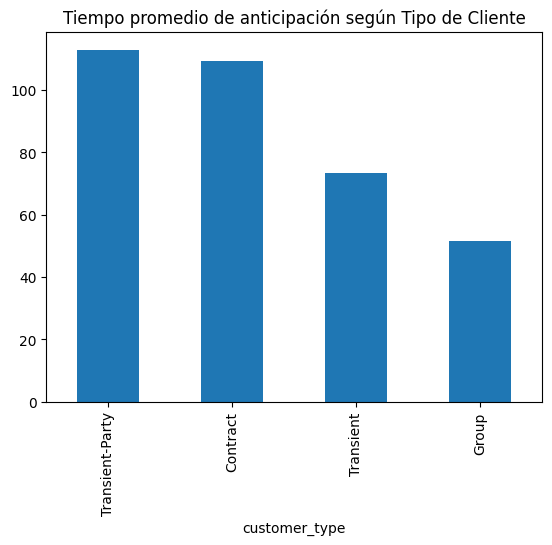

In [ ]:
lead_time_cliente = df_cat_num.groupby('customer_type')['lead_time'].mean().sort_values(ascending=False)
lead_time_cliente.plot.bar(title='Tiempo promedio de anticipación según Tipo de Cliente')

### 3. ¿Cuál es la tarifa promedio diaria (ADR) según tipo de cliente?

In [ ]:
# Promedio de ADR por tipo de cliente
df_cat_num.groupby('customer_type')['adr'].mean().sort_values(ascending=False)

<ipython-input-207-4154858191>:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_cat_num.groupby('customer_type')['adr'].mean().sort_values(ascending=False)


,adr
customer_type,
Transient,110.036
Contract,92.756
Transient-Party,87.679
Group,84.362


<ipython-input-208-129933037>:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adr_cliente = df_cat_num.groupby('customer_type')['adr'].mean().sort_values(ascending=False)


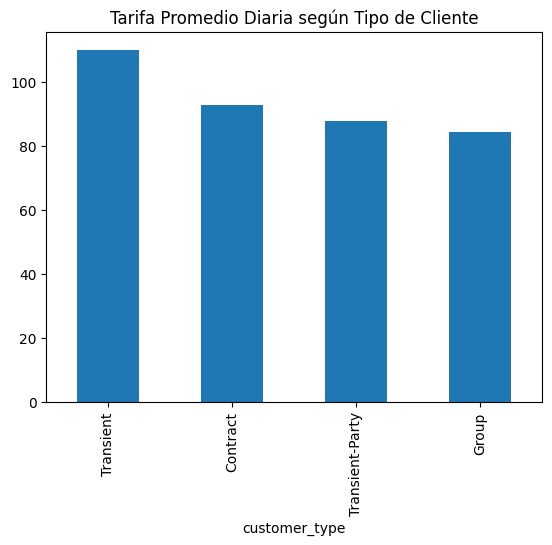

In [ ]:
adr_cliente = df_cat_num.groupby('customer_type')['adr'].mean().sort_values(ascending=False)
adr_cliente.plot.bar(title='Tarifa Promedio Diaria según Tipo de Cliente');

### 4. ¿Cuál es el comportamiento de cambios en reserva (booking_changes) según tipo de cliente?

In [ ]:
# Total y promedio de cambios en reserva por tipo de cliente
df_cat_num.groupby('customer_type')['booking_changes'].agg(['sum', 'count', 'mean']).sort_values(by='mean', ascending=False)


<ipython-input-209-2210658765>:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_cat_num.groupby('customer_type')['booking_changes'].agg(['sum', 'count', 'mean']).sort_values(by='mean', ascending=False)


,sum,count,mean
customer_type,,,
Transient-Party,6959.000,11738,0.593
Group,165.000,544,0.303
Transient,16142.000,71986,0.224
Contract,471.000,3141,0.150


<ipython-input-210-107095793>:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  promedio_cambios = df_cat_num.groupby('customer_type')['booking_changes'].mean()


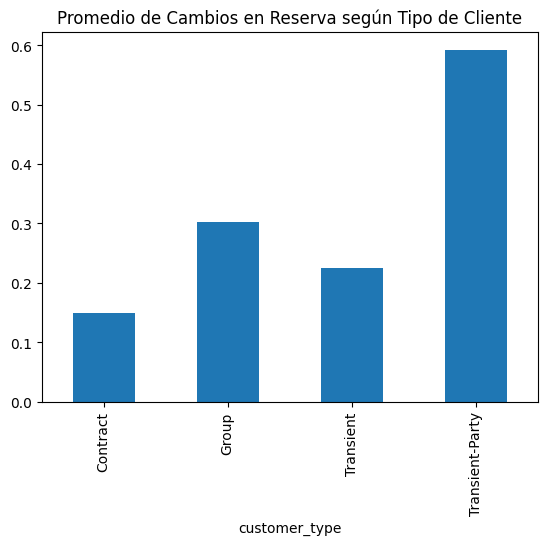

In [ ]:
# Visualización promedio
promedio_cambios = df_cat_num.groupby('customer_type')['booking_changes'].mean()
promedio_cambios.plot.bar(title='Promedio de Cambios en Reserva según Tipo de Cliente');

## Grabar los objetos de datos

In [ ]:
df_cat_num

,hotel,is_canceled,arrival_date_year,arrival_date_month,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,...,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,0,2015.0,July,BB,PRT,Direct,Direct,0.0,C,...,2.0,0.0,0.0,0.0,0.0,3.0,0,0.00,0.0,0.0
1,Resort Hotel,0,2015.0,July,BB,PRT,Direct,Direct,0.0,C,...,2.0,0.0,0.0,0.0,0.0,4.0,0,0.00,0.0,0.0
3,Resort Hotel,0,2015.0,July,BB,GBR,Corporate,Corporate,0.0,A,...,1.0,0.0,0.0,0.0,0.0,0.0,0,75.00,0.0,0.0
4,Resort Hotel,0,2015.0,July,BB,GBR,Online TA,TA/TO,0.0,A,...,2.0,0.0,0.0,0.0,0.0,0.0,0,98.00,0.0,1.0
6,Resort Hotel,0,2015.0,July,BB,PRT,Direct,Direct,0.0,C,...,2.0,0.0,0.0,0.0,0.0,0.0,0,107.00,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,2017.0,August,BB,BEL,Offline TA/TO,TA/TO,0.0,A,...,2.0,0.0,0.0,0.0,0.0,0.0,0,96.14,0.0,0.0
119386,City Hotel,0,2017.0,August,BB,FRA,Online TA,TA/TO,0.0,E,...,3.0,0.0,0.0,0.0,0.0,0.0,0,225.43,0.0,2.0
119387,City Hotel,0,2017.0,August,BB,DEU,Online TA,TA/TO,0.0,D,...,2.0,0.0,0.0,0.0,0.0,0.0,0,157.71,0.0,4.0
119388,City Hotel,0,2017.0,August,BB,GBR,Online TA,TA/TO,0.0,A,...,2.0,0.0,0.0,0.0,0.0,0.0,0,104.40,0.0,0.0


In [ ]:
df_cat_num.to_pickle(str(ARTIFACTS_DIR / 'df_cat_num_fin_EDA.pickle'))

# Data Transformation

## Cargamos las librerías del proyecto

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy as scipy
import seaborn as sns

%matplotlib inline

#Automcompletar rápido
%config IPCompleter.greedy=True
#Desactivar la notación científica
pd.options.display.float_format = '{:.3f}'.format

pd.options.display.max_columns = None

In [ ]:
# Las carpetas se configuran en la primera celda; no se necesita montar Google Drive.


## Abrimos el dataset

In [ ]:
df = pd.read_pickle(str(ARTIFACTS_DIR / 'df_cat_num_fin_EDA.pickle'))
df.reset_index(inplace = True)
df.head(5)

Dividimos en dataframes de categoricas y numericas

In [ ]:
df_cat = df.select_dtypes(exclude='number').copy()
df_num = df.select_dtypes(include='number').copy()

## VARIABLES CATEGÓRICAS

### Conversión de Variables Categóricas con One Hot Encoder

In [ ]:
df_cat

,hotel,is_canceled,arrival_date_year,arrival_date_month,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
0,Resort Hotel,0,2015.000,July,BB,PRT,Direct,Direct,0.000,C,C,No Deposit,Transient,Check-Out,2015-01-07
1,Resort Hotel,0,2015.000,July,BB,PRT,Direct,Direct,0.000,C,C,No Deposit,Transient,Check-Out,2015-01-07
2,Resort Hotel,0,2015.000,July,BB,GBR,Corporate,Corporate,0.000,A,A,No Deposit,Transient,Check-Out,2015-02-07
3,Resort Hotel,0,2015.000,July,BB,GBR,Online TA,TA/TO,0.000,A,A,No Deposit,Transient,Check-Out,2015-03-07
4,Resort Hotel,0,2015.000,July,BB,PRT,Direct,Direct,0.000,C,C,No Deposit,Transient,Check-Out,2015-03-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87404,City Hotel,0,2017.000,August,BB,BEL,Offline TA/TO,TA/TO,0.000,A,A,No Deposit,Transient,Check-Out,2017-06-09
87405,City Hotel,0,2017.000,August,BB,FRA,Online TA,TA/TO,0.000,E,E,No Deposit,Transient,Check-Out,2017-07-09
87406,City Hotel,0,2017.000,August,BB,DEU,Online TA,TA/TO,0.000,D,D,No Deposit,Transient,Check-Out,2017-07-09
87407,City Hotel,0,2017.000,August,BB,GBR,Online TA,TA/TO,0.000,A,A,No Deposit,Transient,Check-Out,2017-07-09


In [ ]:
columnas = ['arrival_date_year','meal','country','market_segment','distribution_channel','reserved_room_type','assigned_room_type',
            'deposit_type','customer_type','hotel','is_repeated_guest']
df[columnas]

,arrival_date_year,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,hotel,is_repeated_guest
0,2015.000,BB,PRT,Direct,Direct,C,C,No Deposit,Transient,Resort Hotel,0.000
1,2015.000,BB,PRT,Direct,Direct,C,C,No Deposit,Transient,Resort Hotel,0.000
2,2015.000,BB,GBR,Corporate,Corporate,A,A,No Deposit,Transient,Resort Hotel,0.000
3,2015.000,BB,GBR,Online TA,TA/TO,A,A,No Deposit,Transient,Resort Hotel,0.000
4,2015.000,BB,PRT,Direct,Direct,C,C,No Deposit,Transient,Resort Hotel,0.000
...,...,...,...,...,...,...,...,...,...,...,...
87404,2017.000,BB,BEL,Offline TA/TO,TA/TO,A,A,No Deposit,Transient,City Hotel,0.000
87405,2017.000,BB,FRA,Online TA,TA/TO,E,E,No Deposit,Transient,City Hotel,0.000
87406,2017.000,BB,DEU,Online TA,TA/TO,D,D,No Deposit,Transient,City Hotel,0.000
87407,2017.000,BB,GBR,Online TA,TA/TO,A,A,No Deposit,Transient,City Hotel,0.000


In [ ]:
from sklearn.preprocessing import OneHotEncoder

oneHE = OneHotEncoder(sparse_output  = False, drop='first', dtype='int64')
df_oneHE = oneHE.fit_transform(df[columnas])

df_oneHE = pd.DataFrame(data = df_oneHE , columns=oneHE.get_feature_names_out())
df_oneHE

,arrival_date_year_2016.0,arrival_date_year_2017.0,meal_FB,meal_HB,meal_SC,meal_Undefined,country_AGO,country_AIA,country_ALB,country_AND,country_ARE,country_ARG,country_ARM,country_ASM,country_ATA,country_ATF,country_AUS,country_AUT,country_AZE,country_BDI,country_BEL,country_BEN,country_BFA,country_BGD,country_BGR,country_BHR,country_BHS,country_BIH,country_BLR,country_BOL,country_BRA,country_BRB,country_BWA,country_CAF,country_CHE,country_CHL,country_CHN,country_CIV,country_CMR,country_CN,country_COL,country_COM,country_CPV,country_CRI,country_CUB,country_CYM,country_CYP,country_CZE,country_DEU,country_DJI,country_DMA,country_DNK,country_DOM,country_DZA,country_ECU,country_EGY,country_ESP,country_EST,country_ETH,country_FIN,country_FJI,country_FRA,country_FRO,country_GAB,country_GBR,country_GEO,country_GGY,country_GHA,country_GIB,country_GLP,country_GNB,country_GRC,country_GTM,country_GUY,country_HKG,country_HND,country_HRV,country_HUN,country_IDN,country_IMN,country_IND,country_IRL,country_IRN,country_IRQ,country_ISL,country_ISR,country_ITA,country_JAM,country_JEY,country_JOR,country_JPN,country_KAZ,country_KEN,country_KHM,country_KIR,country_KNA,country_KOR,country_KWT,country_LAO,country_LBN,country_LBY,country_LCA,country_LIE,country_LKA,country_LTU,country_LUX,country_LVA,country_MAC,country_MAR,country_MCO,country_MDG,country_MDV,country_MEX,country_MKD,country_MLI,country_MLT,country_MMR,country_MNE,country_MOZ,country_MRT,country_MUS,country_MWI,country_MYS,country_MYT,country_NAM,country_NCL,country_NGA,country_NIC,country_NLD,country_NOR,country_NPL,country_NZL,country_No information,country_OMN,country_PAK,country_PAN,country_PER,country_PHL,country_PLW,country_POL,country_PRI,country_PRT,country_PRY,country_PYF,country_QAT,country_ROU,country_RUS,country_RWA,country_SAU,country_SDN,country_SEN,country_SGP,country_SLE,country_SLV,country_SMR,country_SRB,country_STP,country_SUR,country_SVK,country_SVN,country_SWE,country_SYC,country_SYR,country_TGO,country_THA,country_TJK,country_TMP,country_TUN,country_TUR,country_TWN,country_TZA,country_UGA,country_UKR,country_UMI,country_URY,country_USA,country_UZB,country_VEN,country_VGB,country_VNM,country_ZAF,country_ZMB,country_ZWE,market_segment_Complementary,market_segment_Corporate,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,distribution_channel_Direct,distribution_channel_GDS,distribution_channel_TA/TO,reserved_room_type_B,reserved_room_type_C,reserved_room_type_D,reserved_room_type_E,reserved_room_type_F,reserved_room_type_G,reserved_room_type_H,reserved_room_type_L,reserved_room_type_P,assigned_room_type_B,assigned_room_type_C,assigned_room_type_D,assigned_room_type_E,assigned_room_type_F,assigned_room_type_G,assigned_room_type_H,assigned_room_type_I,assigned_room_type_K,assigned_room_type_L,assigned_room_type_P,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,hotel_Resort Hotel,is_repeated_guest_1.0
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0

### Conversión de Variables Categóricas con Ordinal Encoder

In [ ]:
from sklearn.preprocessing import OrdinalEncoder

orden_meses = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

ordEN = OrdinalEncoder(categories=[orden_meses], dtype='int64')
df_ordEN = ordEN.fit_transform(df[['arrival_date_month']])

print(pd.DataFrame(ordEN.categories_).T)
df_ordEN = pd.DataFrame(df_ordEN, columns = ['arrival_date_month'])
df_ordEN

            0
0     January
1    February
2       March
3       April
4         May
5        June
6        July
7      August
8   September
9     October
10   November
11   December


,arrival_date_month
0,6
1,6
2,6
3,6
4,6
...,...
87404,7
87405,7
87406,7
87407,7


In [ ]:
df_arrival_date_month = df['arrival_date_month']
df_arrival_date_month

,arrival_date_month
0,July
1,July
2,July
3,July
4,July
...,...
87404,August
87405,August
87406,August
87407,August


## VARIABLES NUMÉRICAS

### MinMaxScaler

In [ ]:
df_num

,index,lead_time,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
0,0,342.000,27.000,1.000,0.000,0.000,2.000,0.000,0.000,0.000,0.000,3.000,0,0.000,0.000,0.000
1,1,479.000,27.000,1.000,0.000,0.000,2.000,0.000,0.000,0.000,0.000,4.000,0,0.000,0.000,0.000
2,3,13.000,27.000,1.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0,75.000,0.000,0.000
3,4,14.000,27.000,1.000,0.000,2.000,2.000,0.000,0.000,0.000,0.000,0.000,0,98.000,0.000,1.000
4,6,0.000,27.000,1.000,0.000,2.000,2.000,0.000,0.000,0.000,0.000,0.000,0,107.000,0.000,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87404,119385,23.000,35.000,30.000,2.000,5.000,2.000,0.000,0.000,0.000,0.000,0.000,0,96.140,0.000,0.000
87405,119386,102.000,35.000,31.000,2.000,5.000,3.000,0.000,0.000,0.000,0.000,0.000,0,225.430,0.000,2.000
87406,119387,34.000,35.000,31.000,2.000,5.000,2.000,0.000,0.000,0.000,0.000,0.000,0,157.710,0.000,4.000
87407,119388,109.000,35.000,31.000,2.000,5.000,2.000,0.000,0.000,0.000,0.000,0.000,0,104.400,0.000,0.000


In [ ]:
from sklearn.preprocessing import MinMaxScaler

columnas = ['lead_time','arrival_date_week_number','arrival_date_day_of_month','stays_in_weekend_nights',
            'stays_in_week_nights','adults','children','babies','previous_cancellations','previous_bookings_not_canceled',
            'booking_changes','days_in_waiting_list','adr','required_car_parking_spaces','total_of_special_requests']

mms = MinMaxScaler()
mms.fit(df[columnas])
df_mms = mms.transform(df[columnas])
df_mms = pd.DataFrame(data=df_mms, columns=columnas)
df_mms

,lead_time,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
0,0.714,0.500,0.000,0.000,0.000,0.036,0.000,0.000,0.000,0.000,0.143,0.000,0.000,0.000,0.000
1,1.000,0.500,0.000,0.000,0.000,0.036,0.000,0.000,0.000,0.000,0.190,0.000,0.000,0.000,0.000
2,0.027,0.500,0.000,0.000,0.045,0.018,0.000,0.000,0.000,0.000,0.000,0.000,0.224,0.000,0.000
3,0.029,0.500,0.000,0.000,0.091,0.036,0.000,0.000,0.000,0.000,0.000,0.000,0.293,0.000,0.200
4,0.000,0.500,0.000,0.000,0.091,0.036,0.000,0.000,0.000,0.000,0.000,0.000,0.319,0.000,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87404,0.048,0.654,0.967,0.105,0.227,0.036,0.000,0.000,0.000,0.000,0.000,0.000,0.287,0.000,0.000
87405,0.213,0.654,1.000,0.105,0.227,0.055,0.000,0.000,0.000,0.000,0.000,0.000,0.673,0.000,0.400
87406,0.071,0.654,1.000,0.105,0.227,0.036,0.000,0.000,0.000,0.000,0.000,0.000,0.471,0.000,0.800
87407,0.228,0.654,1.000,0.105,0.227,0.036,0.000,0.000,0.000,0.000,0.000,0.000,0.312,0.000,0.000


In [ ]:
df_target = df['is_canceled']
df_target

,is_canceled
0,0
1,0
2,0
3,0
4,0
...,...
87404,0
87405,0
87406,0
87407,0


## Integración de los dataframes

In [ ]:
df_final = pd.concat([df_oneHE,df_ordEN,df_mms,df_target],axis=1)

In [ ]:
df_final

,arrival_date_year_2016.0,arrival_date_year_2017.0,meal_FB,meal_HB,meal_SC,meal_Undefined,country_AGO,country_AIA,country_ALB,country_AND,country_ARE,country_ARG,country_ARM,country_ASM,country_ATA,country_ATF,country_AUS,country_AUT,country_AZE,country_BDI,country_BEL,country_BEN,country_BFA,country_BGD,country_BGR,country_BHR,country_BHS,country_BIH,country_BLR,country_BOL,country_BRA,country_BRB,country_BWA,country_CAF,country_CHE,country_CHL,country_CHN,country_CIV,country_CMR,country_CN,country_COL,country_COM,country_CPV,country_CRI,country_CUB,country_CYM,country_CYP,country_CZE,country_DEU,country_DJI,country_DMA,country_DNK,country_DOM,country_DZA,country_ECU,country_EGY,country_ESP,country_EST,country_ETH,country_FIN,country_FJI,country_FRA,country_FRO,country_GAB,country_GBR,country_GEO,country_GGY,country_GHA,country_GIB,country_GLP,country_GNB,country_GRC,country_GTM,country_GUY,country_HKG,country_HND,country_HRV,country_HUN,country_IDN,country_IMN,country_IND,country_IRL,country_IRN,country_IRQ,country_ISL,country_ISR,country_ITA,country_JAM,country_JEY,country_JOR,country_JPN,country_KAZ,country_KEN,country_KHM,country_KIR,country_KNA,country_KOR,country_KWT,country_LAO,country_LBN,country_LBY,country_LCA,country_LIE,country_LKA,country_LTU,country_LUX,country_LVA,country_MAC,country_MAR,country_MCO,country_MDG,country_MDV,country_MEX,country_MKD,country_MLI,country_MLT,country_MMR,country_MNE,country_MOZ,country_MRT,country_MUS,country_MWI,country_MYS,country_MYT,country_NAM,country_NCL,country_NGA,country_NIC,country_NLD,country_NOR,country_NPL,country_NZL,country_No information,country_OMN,country_PAK,country_PAN,country_PER,country_PHL,country_PLW,country_POL,country_PRI,country_PRT,country_PRY,country_PYF,country_QAT,country_ROU,country_RUS,country_RWA,country_SAU,country_SDN,country_SEN,country_SGP,country_SLE,country_SLV,country_SMR,country_SRB,country_STP,country_SUR,country_SVK,country_SVN,country_SWE,country_SYC,country_SYR,country_TGO,country_THA,country_TJK,country_TMP,country_TUN,country_TUR,country_TWN,country_TZA,country_UGA,country_UKR,country_UMI,country_URY,country_USA,country_UZB,country_VEN,country_VGB,country_VNM,country_ZAF,country_ZMB,country_ZWE,market_segment_Complementary,market_segment_Corporate,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,distribution_channel_Direct,distribution_channel_GDS,distribution_channel_TA/TO,reserved_room_type_B,reserved_room_type_C,reserved_room_type_D,reserved_room_type_E,reserved_room_type_F,reserved_room_type_G,reserved_room_type_H,reserved_room_type_L,reserved_room_type_P,assigned_room_type_B,assigned_room_type_C,assigned_room_type_D,assigned_room_type_E,assigned_room_type_F,assigned_room_type_G,assigned_room_type_H,assigned_room_type_I,assigned_room_type_K,assigned_room_type_L,assigned_room_type_P,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,hotel_Resort Hotel,is_repeated_guest_1.0,arrival_date_month,lead_time,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,is_canceled
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,6,0.714,0.500,0.000,0.000,0.000,0.036,0.000,0.000,0.000,0.000,0.143,0.000,0.000,0.000,0.000,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,

## Grabamos los datos

In [ ]:
df_final.to_pickle(str(ARTIFACTS_DIR / 'df_final_transformacion_actulizado.pickle'))

# Modelización

## Modelo de Regresión Logística

### Cargamos las librerias del proyecto

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

#Automcompletar rápido
%config IPCompleter.greedy=True
#Desactivar la notación científica
pd.options.display.float_format = '{:.3f}'.format

In [ ]:
# Las carpetas se configuran en la primera celda; no se necesita montar Google Drive.


In [ ]:
df_Rlogist = pd.read_pickle(str(ARTIFACTS_DIR / 'df_final_transformacion_actulizado.pickle'))
df_Rlogist.head()

In [ ]:
df_Rlogist.shape

(87409, 236)

### Separamos las variables independientes (X) y la variable a predecir o target (y)

In [ ]:
X = df_Rlogist.drop(columns = ['is_canceled'])
y = df_Rlogist['is_canceled']

In [ ]:
X

,arrival_date_year_2016.0,arrival_date_year_2017.0,meal_FB,meal_HB,meal_SC,meal_Undefined,country_AGO,country_AIA,country_ALB,country_AND,...,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
0,0,0,0,0,0,0,0,0,0,0,...,0.036,0.000,0.000,0.000,0.000,0.143,0.000,0.000,0.000,0.000
1,0,0,0,0,0,0,0,0,0,0,...,0.036,0.000,0.000,0.000,0.000,0.190,0.000,0.000,0.000,0.000
2,0,0,0,0,0,0,0,0,0,0,...,0.018,0.000,0.000,0.000,0.000,0.000,0.000,0.224,0.000,0.000
3,0,0,0,0,0,0,0,0,0,0,...,0.036,0.000,0.000,0.000,0.000,0.000,0.000,0.293,0.000,0.200
4,0,0,0,0,0,0,0,0,0,0,...,0.036,0.000,0.000,0.000,0.000,0.000,0.000,0.319,0.000,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87404,0,1,0,0,0,0,0,0,0,0,...,0.036,0.000,0.000,0.000,0.000,0.000,0.000,0.287,0.000,0.000
87405,0,1,0,0,0,0,0,0,0,0,...,0.055,0.000,0.000,0.000,0.000,0.000,0.000,0.673,0.000,0.400
87406,0,1,0,0,0,0,0,0,0,0,...,0.036,0.000,0.000,0.000,0.000,0.000,0.000,0.471,0.000,0.800
87407,0,1,0,0,0,0,0,0,0,0,...,0.036,0.000,0.000,0.000,0.000,0.000,0.000,0.312,0.000,0.000


In [ ]:
y

,is_canceled
0,0
1,0
2,0
3,0
4,0
...,...
87404,0
87405,0
87406,0
87407,0


### Importamos la librería para el modelo de Regresión Logística

In [ ]:
from sklearn.linear_model import LogisticRegression

### Instanciamos el objeto

In [ ]:
modelo_Reglogistica = LogisticRegression(solver = 'liblinear')

### Separamos el conjunto de datos de entrenamiento (train) y testeo (test)

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Entrenamos el modelo

In [ ]:
modelo_Reglogistica.fit(X_train,y_train)

LogisticRegression(solver='liblinear')

In [ ]:
y_pred_RLog       = modelo_Reglogistica.predict(X_test)
y_pred_RLog_proba = modelo_Reglogistica.predict_proba(X_test)

### Evaluamos al modelo

In [ ]:
from sklearn.metrics import roc_auc_score,confusion_matrix,f1_score,classification_report,\
                            accuracy_score,precision_score,recall_score

In [ ]:
confusion_matrix_RLog = confusion_matrix(y_test,y_pred_RLog)

In [ ]:
pd.DataFrame(confusion_matrix_RLog,columns = ['Prediccion NO','Prediccion SI'], index = ['Real NO','Real SI'])

,Prediccion NO,Prediccion SI
Real NO,11572,1048
Real SI,2601,2261


In [ ]:
#Obtenemos los valors del array
TN = confusion_matrix_RLog[0][0] #TN--> Verdaderos Negativos, son las predicciones negativas correctas
FP = confusion_matrix_RLog[0][1] #FP--> False Positives Son predicciones positivas incorrectas.
FN = confusion_matrix_RLog[1][0] #FN--> False Nagative,
TP = confusion_matrix_RLog[1][1] #TP--> Verdaderos Positivos
print( TN , FP, FN, TP)

11572 1048 2601 2261


**1) ACCURACY**

In [ ]:
acc_Rlog = accuracy_score(y_test,y_pred_RLog)
print(acc_Rlog)

0.7912710216222401


**2) RECALL**

In [ ]:
rec_Rlog = recall_score(y_test,y_pred_RLog)
print(rec_Rlog)

0.46503496503496505


**3) PRECISION**

In [ ]:
prec_RLog = precision_score(y_test,y_pred_RLog)
print(prec_RLog)

0.6832880024176489


**4) ESPECIFICIDAD**

In [ ]:
es = (TN) / (TN + FP)
print(es)

0.9169572107765451


**5) F1-SCORE**

In [ ]:
f1_RLog   = f1_score(y_test,y_pred_RLog)
print(f1_RLog)

0.553420633949333


**6) AUC**

In [ ]:
auc_RLog = roc_auc_score(y_test,y_pred_RLog)
print(auc_RLog)

0.6909960879057551


In [ ]:
# Exportación del modelo de esta sección

#DESCARGAMOS EL MODELO
#import joblib
#joblib.dump(modelo_Reglogistica, str(ARTIFACTS_DIR / 'modelo_reglogistica.pkl'))

In [ ]:
resultados = {
    'Modelo': ['Regresión Logística'],
    'Accuracy': [accuracy_score(y_test, y_pred_RLog)],
    'F1': [f1_score(y_test, y_pred_RLog)],
    'Precision': [precision_score(y_test, y_pred_RLog)],
    'Recall': [recall_score(y_test, y_pred_RLog)],
    'AUC': [roc_auc_score(y_test, y_pred_RLog)]
}
resultados_df = pd.DataFrame(resultados)
resultados_df

,Modelo,Accuracy,F1,Precision,Recall,AUC
0,Regresión Logística,0.791,0.553,0.683,0.465,0.691


## Modelo de Árbol de Decisión

### Cargamos las librerias del proyecto

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

#Automcompletar rápido
%config IPCompleter.greedy=True
#Desactivar la notación científica
pd.options.display.float_format = '{:.3f}'.format

In [ ]:
# Las carpetas se configuran en la primera celda; no se necesita montar Google Drive.


In [ ]:
df_ADec = pd.read_pickle(str(ARTIFACTS_DIR / 'df_final_transformacion_actulizado.pickle'))
df_ADec.head()

In [ ]:
df_ADec.shape

(87409, 236)

### Importamos la librería para el modelo de Árbol de Decisión

In [ ]:
from sklearn.tree import DecisionTreeClassifier

### Instanciamos el objeto

In [ ]:
modelo_DecisionTree = DecisionTreeClassifier(criterion = 'gini', max_depth=5)

### Separamos las variables independientes (X) y la variable a predecir o target (y)

In [ ]:
X = df_ADec.drop(columns = ['is_canceled'])
y = df_ADec['is_canceled']

In [ ]:
X

,arrival_date_year_2016.0,arrival_date_year_2017.0,meal_FB,meal_HB,meal_SC,meal_Undefined,country_AGO,country_AIA,country_ALB,country_AND,country_ARE,country_ARG,country_ARM,country_ASM,country_ATA,country_ATF,country_AUS,country_AUT,country_AZE,country_BDI,country_BEL,country_BEN,country_BFA,country_BGD,country_BGR,country_BHR,country_BHS,country_BIH,country_BLR,country_BOL,country_BRA,country_BRB,country_BWA,country_CAF,country_CHE,country_CHL,country_CHN,country_CIV,country_CMR,country_CN,country_COL,country_COM,country_CPV,country_CRI,country_CUB,country_CYM,country_CYP,country_CZE,country_DEU,country_DJI,country_DMA,country_DNK,country_DOM,country_DZA,country_ECU,country_EGY,country_ESP,country_EST,country_ETH,country_FIN,country_FJI,country_FRA,country_FRO,country_GAB,country_GBR,country_GEO,country_GGY,country_GHA,country_GIB,country_GLP,country_GNB,country_GRC,country_GTM,country_GUY,country_HKG,country_HND,country_HRV,country_HUN,country_IDN,country_IMN,country_IND,country_IRL,country_IRN,country_IRQ,country_ISL,country_ISR,country_ITA,country_JAM,country_JEY,country_JOR,country_JPN,country_KAZ,country_KEN,country_KHM,country_KIR,country_KNA,country_KOR,country_KWT,country_LAO,country_LBN,country_LBY,country_LCA,country_LIE,country_LKA,country_LTU,country_LUX,country_LVA,country_MAC,country_MAR,country_MCO,country_MDG,country_MDV,country_MEX,country_MKD,country_MLI,country_MLT,country_MMR,country_MNE,country_MOZ,country_MRT,country_MUS,country_MWI,country_MYS,country_MYT,country_NAM,country_NCL,country_NGA,country_NIC,country_NLD,country_NOR,country_NPL,country_NZL,country_No information,country_OMN,country_PAK,country_PAN,country_PER,country_PHL,country_PLW,country_POL,country_PRI,country_PRT,country_PRY,country_PYF,country_QAT,country_ROU,country_RUS,country_RWA,country_SAU,country_SDN,country_SEN,country_SGP,country_SLE,country_SLV,country_SMR,country_SRB,country_STP,country_SUR,country_SVK,country_SVN,country_SWE,country_SYC,country_SYR,country_TGO,country_THA,country_TJK,country_TMP,country_TUN,country_TUR,country_TWN,country_TZA,country_UGA,country_UKR,country_UMI,country_URY,country_USA,country_UZB,country_VEN,country_VGB,country_VNM,country_ZAF,country_ZMB,country_ZWE,market_segment_Complementary,market_segment_Corporate,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,distribution_channel_Direct,distribution_channel_GDS,distribution_channel_TA/TO,reserved_room_type_B,reserved_room_type_C,reserved_room_type_D,reserved_room_type_E,reserved_room_type_F,reserved_room_type_G,reserved_room_type_H,reserved_room_type_L,reserved_room_type_P,assigned_room_type_B,assigned_room_type_C,assigned_room_type_D,assigned_room_type_E,assigned_room_type_F,assigned_room_type_G,assigned_room_type_H,assigned_room_type_I,assigned_room_type_K,assigned_room_type_L,assigned_room_type_P,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,hotel_Resort Hotel,is_repeated_guest_1.0,arrival_date_month,lead_time,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,6,0.714,0.500,0.000,0.000,0.000,0.036,0.000,0.000,0.000,0.000,0.143,0.000,0.000,0.000,0.000
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,

In [ ]:
y

,is_canceled
0,0
1,0
2,0
3,0
4,0
...,...
87404,0
87405,0
87406,0
87407,0


### Separamos el conjunto de datos de entrenamiento (train) y testeo (test)

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Entrenamos el modelo

In [ ]:
modelo_DecisionTree.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=5)

### Visualizamos el árbol

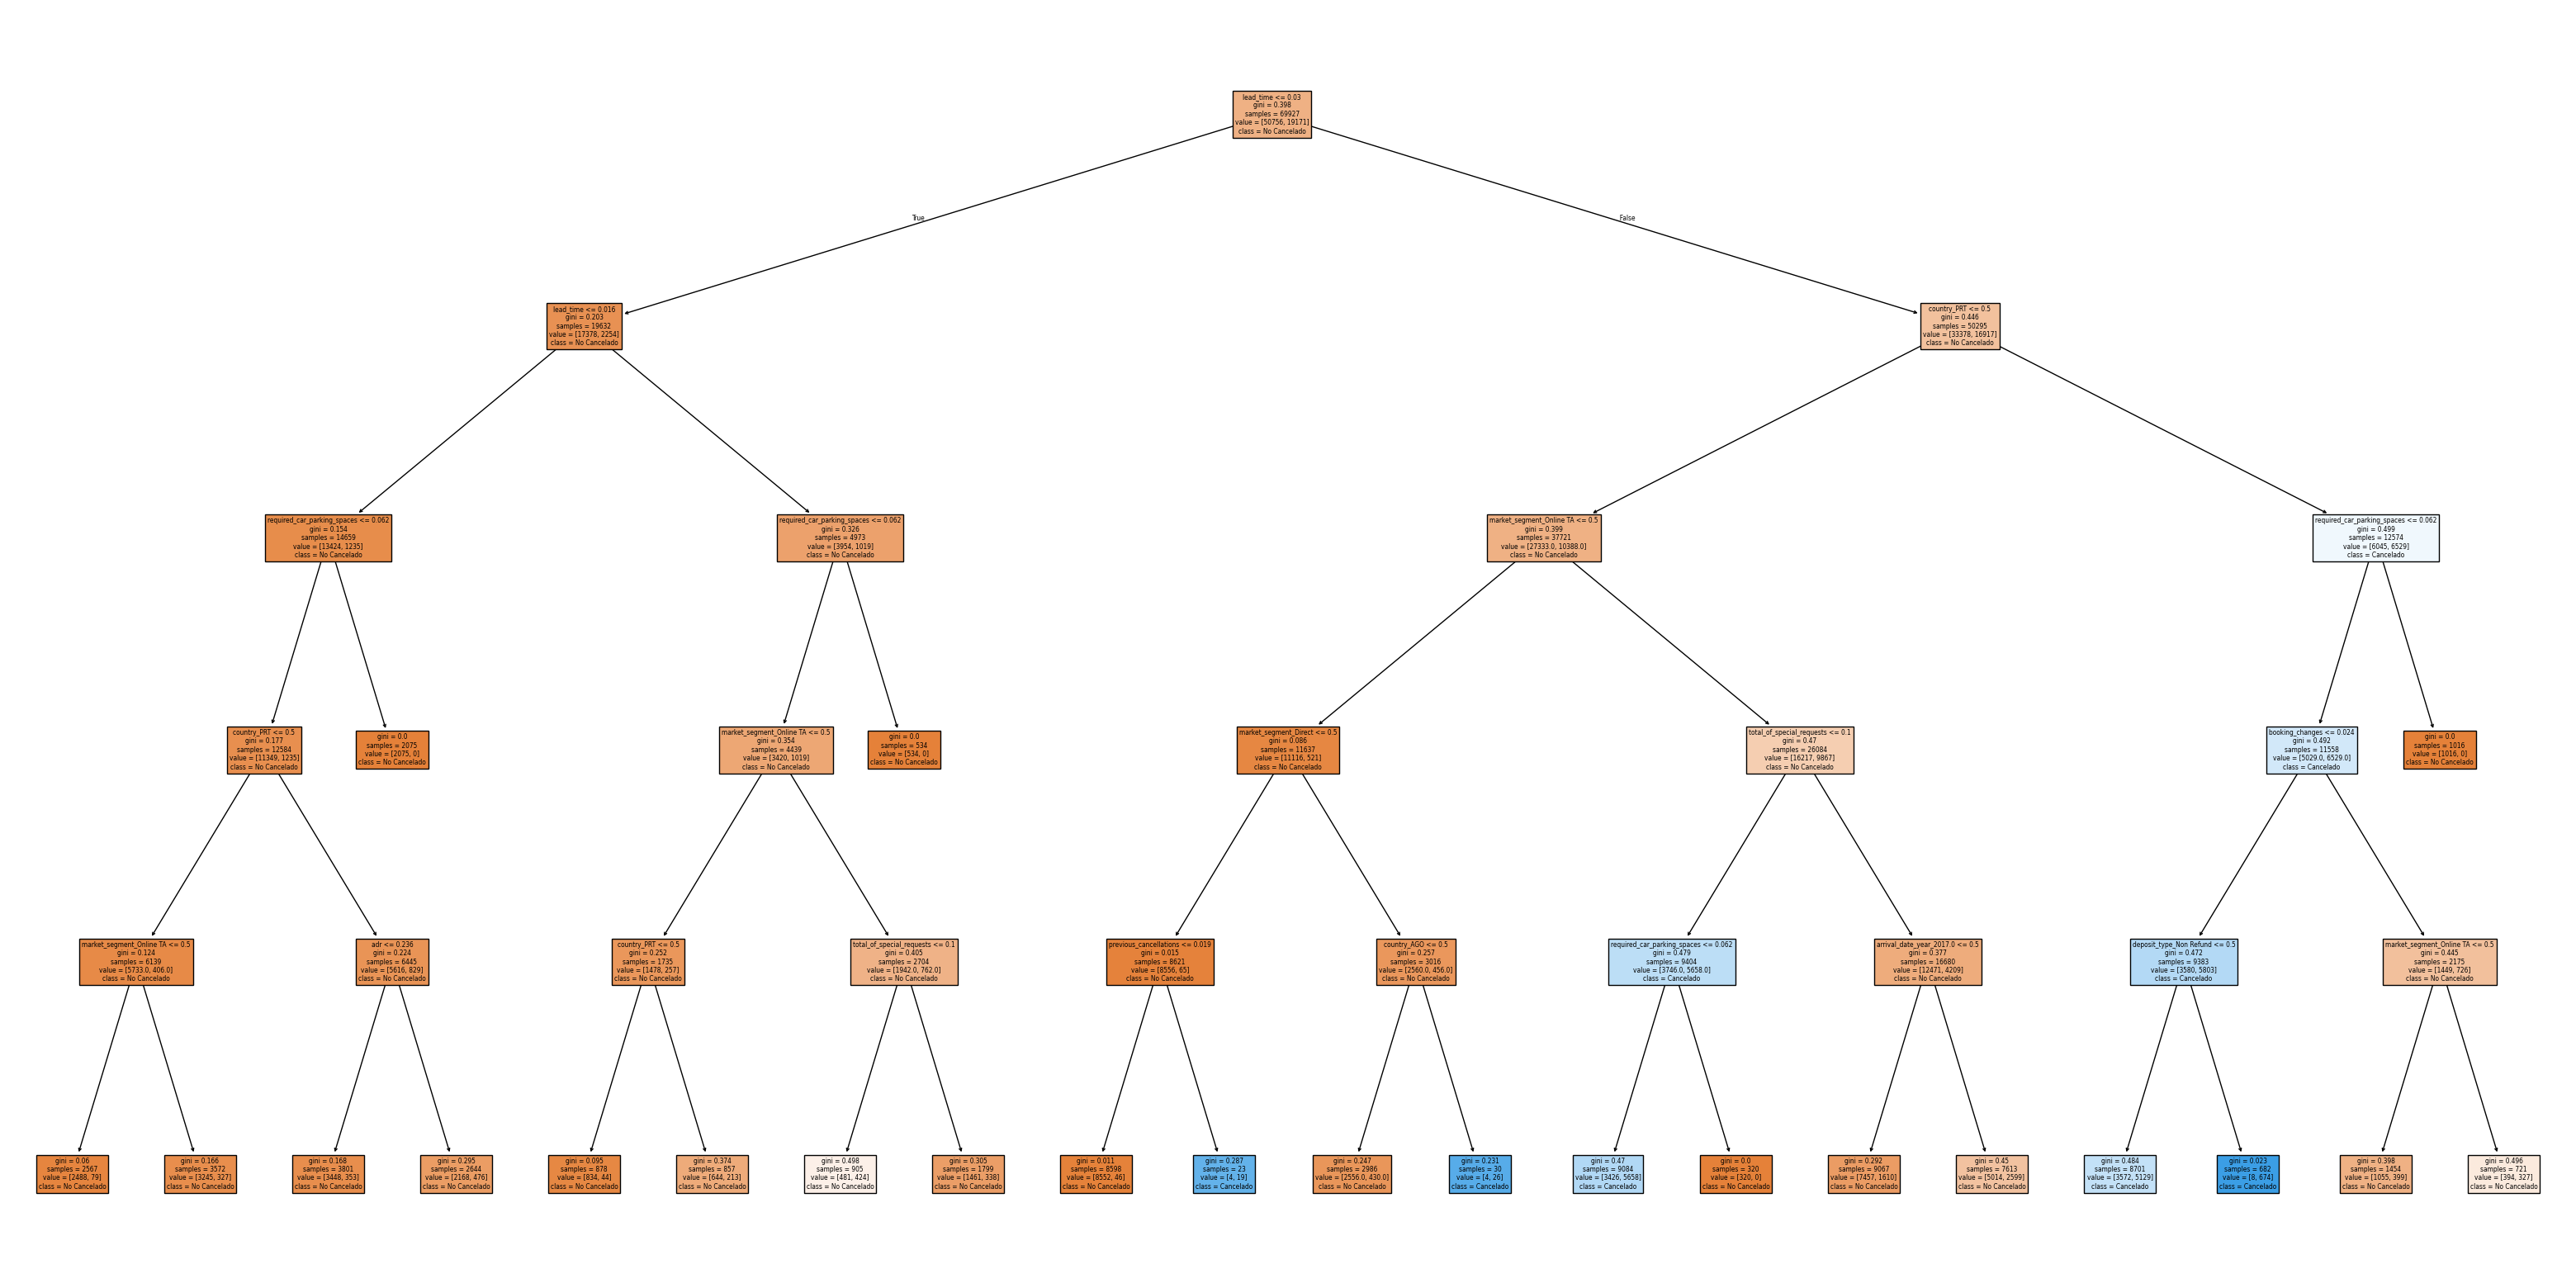

In [ ]:
from sklearn.tree import plot_tree

fig = plt.figure(figsize=(40,20))
_ = plot_tree(modelo_DecisionTree,
                   feature_names=X.columns,
                   class_names=['No Cancelado','Cancelado'],
                   filled=True)

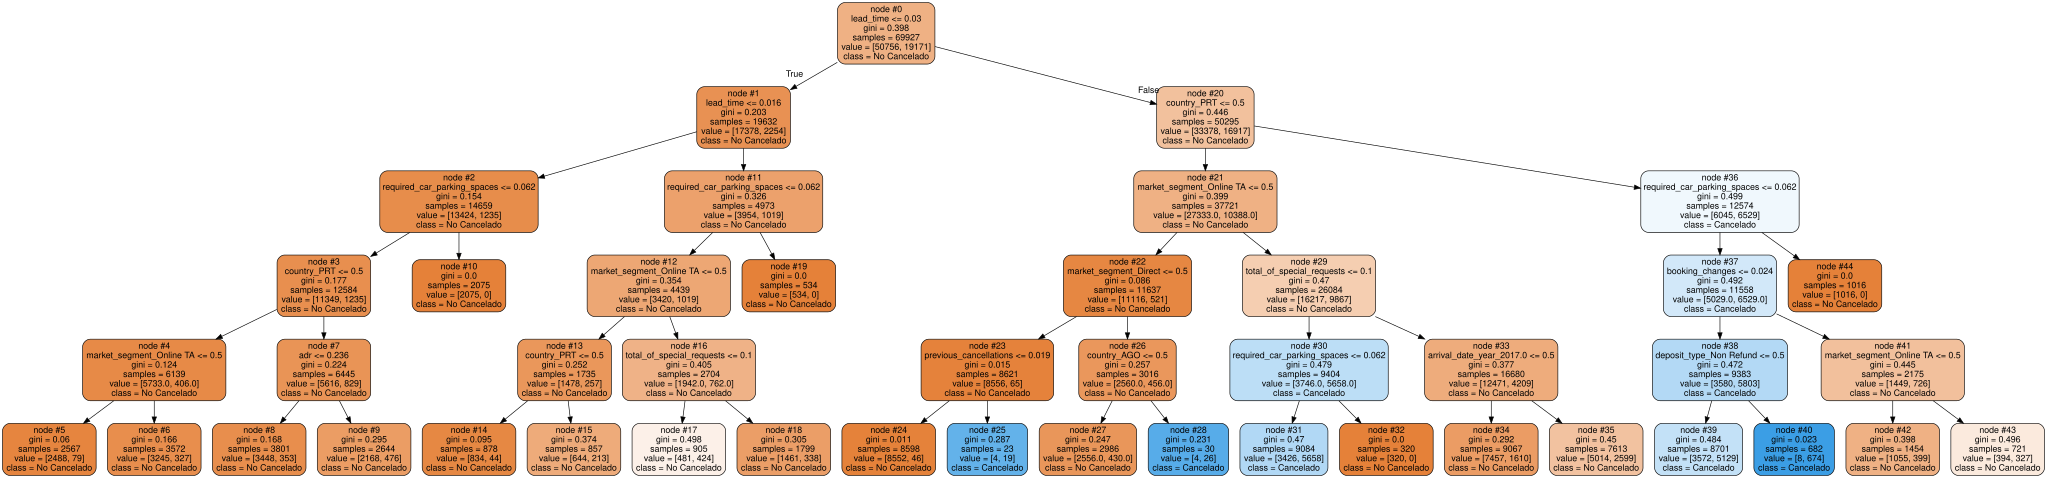

In [ ]:
from sklearn import tree
import graphviz

dot_data = tree.export_graphviz(modelo_DecisionTree, out_file=None,
                                feature_names=X.columns,
                                node_ids=True,
                                rounded=True,
                                class_names=['No Cancelado','Cancelado'],
                                filled=True)

graph = graphviz.Source(dot_data, format="png")
graph

In [ ]:
modelo_DecisionTree.get_depth()

5

### Evaluación del modelo

In [ ]:
from sklearn.metrics import roc_auc_score,confusion_matrix,f1_score,classification_report,\
                            accuracy_score,precision_score,recall_score

In [ ]:
y_pred_DecisionTree       = modelo_DecisionTree.predict(X_test)
print(y_pred_DecisionTree)

[1 1 0 ... 1 1 1]


In [ ]:
confusion_matrix_DesicionTree = confusion_matrix(y_test,y_pred_DecisionTree)

In [ ]:
pd.DataFrame(confusion_matrix_DesicionTree,columns = ['Prediccion NO','Prediccion SI'], index = ['Real NO','Real SI'])

,Prediccion NO,Prediccion SI
Real NO,10851,1769
Real SI,1945,2917


In [ ]:
TN = confusion_matrix_DesicionTree[0][0]
FP = confusion_matrix_DesicionTree[0][1]
FN = confusion_matrix_DesicionTree[1][0]
TP = confusion_matrix_DesicionTree[1][1]
print( TN , FP, FN, TP)

10851 1769 1945 2917


In [ ]:
acc_DesicionTree  = accuracy_score(y_test,y_pred_DecisionTree)
f1_DesicionTree   = f1_score(y_test,y_pred_DecisionTree)
prec_DesicionTree = precision_score(y_test, y_pred_DecisionTree)
rec_DesicionTree  = recall_score(y_test, y_pred_DecisionTree)
auc_DesicionTree  = roc_auc_score(y_test,y_pred_DecisionTree)

In [ ]:
results = pd.DataFrame([['Árbol de decisión', acc_DesicionTree,f1_DesicionTree,prec_DesicionTree,rec_DesicionTree,auc_DesicionTree]],
                       columns = ['Model','Accuracy','F1','Precision','Recall','AUC'])

results

,Model,Accuracy,F1,Precision,Recall,AUC
0,Árbol de decisión,0.788,0.611,0.622,0.600,0.730


## Modelo Random Forest

### Cargamos las librerias del proyecto

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

#Automcompletar rápido
%config IPCompleter.greedy=True
#Desactivar la notación científica
pd.options.display.float_format = '{:.3f}'.format

In [ ]:
# Las carpetas se configuran en la primera celda; no se necesita montar Google Drive.


In [ ]:
df_RForest = pd.read_pickle(str(ARTIFACTS_DIR / 'df_final_transformacion_actulizado.pickle'))
df_RForest.head()

In [ ]:
df_RForest.shape

(87409, 236)

### Separamos las variables independientes (X) y la variable a predecir o target (y)

In [ ]:
X = df_RForest.drop(columns = ['is_canceled'], axis = 1)
y = df_RForest['is_canceled']

In [ ]:
X

,arrival_date_year_2016.0,arrival_date_year_2017.0,meal_FB,meal_HB,meal_SC,meal_Undefined,country_AGO,country_AIA,country_ALB,country_AND,country_ARE,country_ARG,country_ARM,country_ASM,country_ATA,country_ATF,country_AUS,country_AUT,country_AZE,country_BDI,country_BEL,country_BEN,country_BFA,country_BGD,country_BGR,country_BHR,country_BHS,country_BIH,country_BLR,country_BOL,country_BRA,country_BRB,country_BWA,country_CAF,country_CHE,country_CHL,country_CHN,country_CIV,country_CMR,country_CN,country_COL,country_COM,country_CPV,country_CRI,country_CUB,country_CYM,country_CYP,country_CZE,country_DEU,country_DJI,country_DMA,country_DNK,country_DOM,country_DZA,country_ECU,country_EGY,country_ESP,country_EST,country_ETH,country_FIN,country_FJI,country_FRA,country_FRO,country_GAB,country_GBR,country_GEO,country_GGY,country_GHA,country_GIB,country_GLP,country_GNB,country_GRC,country_GTM,country_GUY,country_HKG,country_HND,country_HRV,country_HUN,country_IDN,country_IMN,country_IND,country_IRL,country_IRN,country_IRQ,country_ISL,country_ISR,country_ITA,country_JAM,country_JEY,country_JOR,country_JPN,country_KAZ,country_KEN,country_KHM,country_KIR,country_KNA,country_KOR,country_KWT,country_LAO,country_LBN,country_LBY,country_LCA,country_LIE,country_LKA,country_LTU,country_LUX,country_LVA,country_MAC,country_MAR,country_MCO,country_MDG,country_MDV,country_MEX,country_MKD,country_MLI,country_MLT,country_MMR,country_MNE,country_MOZ,country_MRT,country_MUS,country_MWI,country_MYS,country_MYT,country_NAM,country_NCL,country_NGA,country_NIC,country_NLD,country_NOR,country_NPL,country_NZL,country_No information,country_OMN,country_PAK,country_PAN,country_PER,country_PHL,country_PLW,country_POL,country_PRI,country_PRT,country_PRY,country_PYF,country_QAT,country_ROU,country_RUS,country_RWA,country_SAU,country_SDN,country_SEN,country_SGP,country_SLE,country_SLV,country_SMR,country_SRB,country_STP,country_SUR,country_SVK,country_SVN,country_SWE,country_SYC,country_SYR,country_TGO,country_THA,country_TJK,country_TMP,country_TUN,country_TUR,country_TWN,country_TZA,country_UGA,country_UKR,country_UMI,country_URY,country_USA,country_UZB,country_VEN,country_VGB,country_VNM,country_ZAF,country_ZMB,country_ZWE,market_segment_Complementary,market_segment_Corporate,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,distribution_channel_Direct,distribution_channel_GDS,distribution_channel_TA/TO,reserved_room_type_B,reserved_room_type_C,reserved_room_type_D,reserved_room_type_E,reserved_room_type_F,reserved_room_type_G,reserved_room_type_H,reserved_room_type_L,reserved_room_type_P,assigned_room_type_B,assigned_room_type_C,assigned_room_type_D,assigned_room_type_E,assigned_room_type_F,assigned_room_type_G,assigned_room_type_H,assigned_room_type_I,assigned_room_type_K,assigned_room_type_L,assigned_room_type_P,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,hotel_Resort Hotel,is_repeated_guest_1.0,arrival_date_month,lead_time,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,6,0.714,0.500,0.000,0.000,0.000,0.036,0.000,0.000,0.000,0.000,0.143,0.000,0.000,0.000,0.000
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,

In [ ]:
y

,is_canceled
0,0
1,0
2,0
3,0
4,0
...,...
87404,0
87405,0
87406,0
87407,0


### Separamos el conjunto de datos de entrenamiento (train) y testeo (test)

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(69927, 235)
(17482, 235)
(69927,)
(17482,)


### Modelo

In [ ]:
#Importamos el modelo
from sklearn.ensemble import RandomForestClassifier

In [ ]:
#Instanciamos el modelo
modelo_RandomForest = RandomForestClassifier()

In [ ]:
#Entrenamos el modelo
modelo_RandomForest.fit(X_train,y_train)

RandomForestClassifier()

In [ ]:
#Predecimos usando los datos de test
y_pred_RandomForest       = modelo_RandomForest.predict(X_test)
y_pred_RandomForest_proba = modelo_RandomForest.predict_proba(X_test)

### Evaluamos al modelo

In [ ]:
#Importamos las métricas
from sklearn.metrics import roc_auc_score,confusion_matrix,f1_score,classification_report,\
                            accuracy_score,precision_score,recall_score

In [ ]:
confusion_matrix_RandomForest = confusion_matrix(y_test,y_pred_RandomForest)

In [ ]:
#Mostrar el confusion matrix como dataframe
pd.DataFrame(confusion_matrix_RandomForest,columns = ['Prediccion NO','Prediccion SI'], index = ['Real NO','Real SI'])

,Prediccion NO,Prediccion SI
Real NO,11718,915
Real SI,1903,2946


In [ ]:
TN = confusion_matrix_RandomForest[0][0]
FP = confusion_matrix_RandomForest[0][1]
FN = confusion_matrix_RandomForest[1][0]
TP = confusion_matrix_RandomForest[1][1]
print( TN , FP, FN, TP)

11718 915 1903 2946


In [ ]:
acc_RandomForest  = accuracy_score(y_test,y_pred_RandomForest)
f1_RandomForest   = f1_score(y_test,y_pred_RandomForest)
prec_RandomForest = precision_score(y_test, y_pred_RandomForest)
rec_RandomForest  = recall_score(y_test, y_pred_RandomForest)
auc_RandomForest  = roc_auc_score(y_test,y_pred_RandomForest_proba[:,1])

In [ ]:
results = pd.DataFrame([['Random Forest', acc_RandomForest,f1_RandomForest,prec_RandomForest,rec_RandomForest,auc_RandomForest]],
                       columns = ['Model','Accuracy','F1','Precision','Recall','AUC'])

In [ ]:
results

,Model,Accuracy,F1,Precision,Recall,AUC
0,Random Forest,0.839,0.676,0.763,0.608,0.900


### Vemos los parámetros

In [ ]:
#Número de arboles generados
modelo_RandomForest.n_estimators

100

In [ ]:
#Numero de variables usadas
modelo_RandomForest.n_features_in_

235

In [ ]:
#Arbol en indice 5
estimator = modelo_RandomForest.estimators_[5]

### Visualizamos el árbol

In [ ]:
from sklearn import tree

In [ ]:
fig = plt.figure(figsize=(40,20))
_ = tree.plot_tree(estimator,
                   feature_names=X.columns,
                   class_names=['No cancelada','Cancelada'],node_ids=True,
                   filled=True)

Output hidden; open in https://colab.research.google.com to view.

## Modelo XGBoost

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

#Automcompletar rápido
%config IPCompleter.greedy=True
#Desactivar la notación científica
pd.options.display.float_format = '{:.3f}'.format

In [ ]:
# Las carpetas se configuran en la primera celda; no se necesita montar Google Drive.


In [ ]:
df_XGBoost = pd.read_pickle(str(ARTIFACTS_DIR / 'df_final_transformacion_actulizado.pickle'))
df_XGBoost.head()

In [ ]:
df_XGBoost.shape

(87409, 236)

In [ ]:
X = df_XGBoost.drop(columns = ['is_canceled'])
y = df_XGBoost['is_canceled']

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(69927, 235)
(17482, 235)
(69927,)
(17482,)


In [ ]:
from xgboost import XGBClassifier
modelo_XGBoost = XGBClassifier(eval_metric="auc", use_label_encoder=False)

In [ ]:
modelo_XGBoost.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=True)

[0]	validation_0-auc:0.84308


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [04:23:48] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


[1]	validation_0-auc:0.85355
[2]	validation_0-auc:0.85644
[3]	validation_0-auc:0.86002
[4]	validation_0-auc:0.86205
[5]	validation_0-auc:0.86344
[6]	validation_0-auc:0.86610
[7]	validation_0-auc:0.86724
[8]	validation_0-auc:0.86812
[9]	validation_0-auc:0.86935
[10]	validation_0-auc:0.87213
[11]	validation_0-auc:0.87533
[12]	validation_0-auc:0.87667
[13]	validation_0-auc:0.87732
[14]	validation_0-auc:0.87936
[15]	validation_0-auc:0.87977
[16]	validation_0-auc:0.88194
[17]	validation_0-auc:0.88235
[18]	validation_0-auc:0.88288
[19]	validation_0-auc:0.88339
[20]	validation_0-auc:0.88464
[21]	validation_0-auc:0.88493
[22]	validation_0-auc:0.88585
[23]	validation_0-auc:0.88737
[24]	validation_0-auc:0.88779
[25]	validation_0-auc:0.88839
[26]	validation_0-auc:0.88860
[27]	validation_0-auc:0.88872
[28]	validation_0-auc:0.88970
[29]	validation_0-auc:0.88974
[30]	validation_0-auc:0.89142
[31]	validation_0-auc:0.89183
[32]	validation_0-auc:0.89215
[33]	validation_0-auc:0.89277
[34]	validation_0-a

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='auc', feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)

In [ ]:
# Predecimos en el conjunto de prueba
y_pred_XGBoost       = modelo_XGBoost.predict(X_test)
y_pred_XGBoost_proba = modelo_XGBoost.predict_proba(X_test)
y_pred_XGBoost_proba[:,1][:10]

array([1.2487264e-02, 3.5770293e-03, 2.0811252e-01, 7.0529350e-05,
       3.9944609e-04, 6.6236359e-01, 4.1847914e-02, 8.3934627e-02,
       9.7053349e-02, 3.5629457e-01], dtype=float32)

In [ ]:
#Como apoyo podemos crear una tabla con los valores reales (y_test) vs las predicciones(y_pred)
df_comparar = pd.DataFrame()
df_comparar = X_test.copy()
df_comparar["y_test_XGBoost"] = y_test
df_comparar["y_pred_XGBoost"] = y_pred_XGBoost
df_comparar["y_pred_proba_XGBoost"] = y_pred_XGBoost_proba[:,1][:]
df_comparar.head()

,arrival_date_year_2016.0,arrival_date_year_2017.0,meal_FB,meal_HB,meal_SC,meal_Undefined,country_AGO,country_AIA,country_ALB,country_AND,...,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,y_test_XGBoost,y_pred_XGBoost,y_pred_proba_XGBoost
70478,1,0,0,0,0,0,0,0,0,0,...,0.000,0.000,0.048,1.000,0.269,0.000,0.000,0,0,0.012
20574,1,0,0,0,0,0,0,0,0,0,...,0.000,0.000,0.000,0.000,0.143,0.000,0.000,0,0,0.004
63457,1,0,0,0,0,0,0,0,0,0,...,0.000,0.000,0.000,0.000,0.379,0.000,0.200,0,0,0.208
11753,1,0,0,0,0,0,0,0,0,0,...,0.000,0.097,0.000,0.000,0.143,0.125,0.000,0,0,0.000
18833,1,0,0,0,0,0,0,0,0,0,...,0.000,0.000,0.143,0.000,0.296,0.125,0.000,0,0,0.000


In [ ]:
#Importamos las métricas
from sklearn.metrics import roc_auc_score,confusion_matrix,f1_score,classification_report,\
                            accuracy_score,precision_score,recall_score

In [ ]:
confusion_matrix_XGBoost = confusion_matrix(y_test,y_pred_XGBoost)

In [ ]:
#Mostrar el confusion matrix como dataframe
pd.DataFrame(confusion_matrix_XGBoost,columns = ['Prediccion NO','Prediccion SI'], index = ['Real NO','Real SI'])

,Prediccion NO,Prediccion SI
Real NO,11550,1083
Real SI,1750,3099


In [ ]:
acc_XGBoost  = accuracy_score(y_test,y_pred_XGBoost) #Accuracy
f1_XGBoost   = f1_score(y_test,y_pred_XGBoost) #F1-score
prec_XGBoost = precision_score(y_test, y_pred_XGBoost) #Precision
rec_XGBoost  = recall_score(y_test, y_pred_XGBoost) #Recall
auc_XGBoost  = roc_auc_score(y_test,y_pred_XGBoost_proba[:,1]) #AUC

In [ ]:
results = pd.DataFrame([['XGBoost', acc_XGBoost,f1_XGBoost,prec_XGBoost,rec_XGBoost,auc_XGBoost]],
                       columns = ['Model','Accuracy','F1','Precision','Recall','AUC'])

results

,Model,Accuracy,F1,Precision,Recall,AUC
0,XGBoost,0.838,0.686,0.741,0.639,0.903


In [ ]:
#VER PARAMETROS

In [ ]:
modelo_XGBoost.get_params()

{'objective': 'binary:logistic',
 'base_score': None,
 'booster': None,
 'callbacks': None,
 'colsample_bylevel': None,
 'colsample_bynode': None,
 'colsample_bytree': None,
 'device': None,
 'early_stopping_rounds': None,
 'enable_categorical': False,
 'eval_metric': 'auc',
 'feature_types': None,
 'gamma': None,
 'grow_policy': None,
 'importance_type': None,
 'interaction_constraints': None,
 'learning_rate': None,
 'max_bin': None,
 'max_cat_threshold': None,
 'max_cat_to_onehot': None,
 'max_delta_step': None,
 'max_depth': None,
 'max_leaves': None,
 'min_child_weight': None,
 'missing': nan,
 'monotone_constraints': None,
 'multi_strategy': None,
 'n_estimators': None,
 'n_jobs': None,
 'num_parallel_tree': None,
 'random_state': None,
 'reg_alpha': None,
 'reg_lambda': None,
 'sampling_method': None,
 'scale_pos_weight': None,
 'subsample': None,
 'tree_method': None,
 'validate_parameters': None,
 'verbosity': None,
 'use_label_encoder': False}

In [ ]:
#Número de arboles generados
modelo_XGBoost.n_estimators

In [ ]:
#Numero de variables usadas
modelo_XGBoost.n_features_in_

235

In [ ]:
# Exportación del modelo de esta sección

#DESCARGAMOS EL MODELO
import joblib
joblib.dump(modelo_XGBoost, str(ARTIFACTS_DIR / 'modelo_XGBoost_hotel.pkl'))

# Optimización

## Feature Selection - Técnica de Random Forest

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel

In [ ]:
# Las carpetas se configuran en la primera celda; no se necesita montar Google Drive.


In [ ]:
df_Feature_Selection = pd.read_pickle(str(ARTIFACTS_DIR / 'df_final_transformacion_actulizado.pickle'))
df_Feature_Selection

In [ ]:
df_Feature_Selection.shape

(87409, 236)

Separamos las predictoras vs la target

In [ ]:
X = df_Feature_Selection.drop(['is_canceled'], axis = 1)
y = df_Feature_Selection['is_canceled']

Importamos el train_test_split

In [ ]:
from sklearn.model_selection import train_test_split

Separamos Train y test

In [ ]:
X_train,X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

Se va a utlizar la selección de características (Feature Selection)

In [ ]:
sel = SelectFromModel(RandomForestClassifier(n_estimators = 1000))
sel.fit(X_train, y_train)

SelectFromModel(estimator=RandomForestClassifier(n_estimators=1000))

Se obtiene la máscara de booleanos que indica las características que han sido seleccionadas

In [ ]:
sel.get_support()

array([ True,  True, False,  True,  True, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False,  True, False, False, False, False, False,
       False, False,  True, False, False, False, False,  True, False,
       False,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False,

columnas seleccionadas por el modelo

In [ ]:
selected_feat= X_train.columns[(sel.get_support())]
selected_feat

Index(['arrival_date_year_2016.0', 'arrival_date_year_2017.0', 'meal_HB',
       'meal_SC', 'country_DEU', 'country_ESP', 'country_FRA', 'country_GBR',
       'country_PRT', 'market_segment_Direct', 'market_segment_Offline TA/TO',
       'market_segment_Online TA', 'distribution_channel_Direct',
       'distribution_channel_TA/TO', 'reserved_room_type_D',
       'reserved_room_type_E', 'assigned_room_type_D', 'assigned_room_type_E',
       'deposit_type_Non Refund', 'customer_type_Transient',
       'customer_type_Transient-Party', 'hotel_Resort Hotel',
       'arrival_date_month', 'lead_time', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'previous_cancellations',
       'previous_bookings_not_canceled', 'booking_changes', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests'],
      dtype='object')

In [ ]:
print(len(selected_feat))

36


Se Obtiene la importancia de las características del estimador

In [ ]:
sel.estimator_.feature_importances_

array([1.40148601e-02, 1.09963856e-02, 7.17578839e-04, 7.62551792e-03,
       8.16398745e-03, 7.10077465e-04, 1.78686362e-03, 3.92169029e-06,
       1.68287474e-05, 4.31150559e-05, 4.58264017e-04, 5.50106020e-04,
       2.30576400e-05, 3.35951509e-06, 3.35365841e-06, 9.55223115e-06,
       1.00354731e-03, 1.86181218e-03, 5.71734235e-05, 9.36983740e-07,
       3.09394980e-03, 2.27310667e-05, 7.62422376e-07, 4.92632443e-05,
       1.83863520e-04, 2.12462071e-05, 1.27492353e-06, 5.10795034e-05,
       8.97476723e-05, 3.86855498e-06, 3.60330495e-03, 7.42539394e-07,
       0.00000000e+00, 2.99369963e-06, 2.96232682e-03, 1.56919711e-04,
       2.61234263e-03, 2.99127973e-05, 3.62225785e-05, 2.16010377e-03,
       3.27007135e-04, 1.64346248e-05, 7.73138064e-05, 2.76278334e-05,
       6.70798194e-06, 0.00000000e+00, 1.52131124e-04, 4.60532249e-04,
       5.96827410e-03, 0.00000000e+00, 1.64853142e-06, 9.65842661e-04,
       3.24256109e-05, 2.18762588e-04, 1.74168146e-04, 9.62605811e-05,
      

Calculamos el promedio de los scores

In [ ]:
sel.estimator_.feature_importances_.mean()

np.float64(0.00425531914893617)

Listamos las caracteristas más relevantes según su score

In [ ]:
fselection = pd.DataFrame(data = sel.estimator_.feature_importances_.reshape(1,235), columns = X_train.columns)
fselection.T.sort_values(by = 0, ascending = False)

,0
lead_time,0.136
adr,0.096
arrival_date_day_of_month,0.073
arrival_date_week_number,0.068
total_of_special_requests,0.059
...,...
country_GUY,0.000
country_DJI,0.000
country_BWA,0.000
country_CYM,0.000


In [ ]:
top36 = (fselection.T.sort_values(by=0, ascending=False).head(36))
print(top36)

                                   0
lead_time                      0.136
adr                            0.096
arrival_date_day_of_month      0.073
arrival_date_week_number       0.068
total_of_special_requests      0.059
stays_in_week_nights           0.050
arrival_date_month             0.044
country_PRT                    0.043
stays_in_weekend_nights        0.032
required_car_parking_spaces    0.027
market_segment_Online TA       0.025
booking_changes                0.019
adults                         0.018
previous_cancellations         0.015
market_segment_Offline TA/TO   0.015
arrival_date_year_2016.0       0.014
deposit_type_Non Refund        0.014
customer_type_Transient        0.013
hotel_Resort Hotel             0.013
assigned_room_type_D           0.011
arrival_date_year_2017.0       0.011
children                       0.010
country_GBR                    0.009
reserved_room_type_D           0.009
customer_type_Transient-Party  0.009
distribution_channel_TA/TO     0.009
m

## Hiperparametrización

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

#Automcompletar rápido
%config IPCompleter.greedy=True
#Desactivar la notación científica
pd.options.display.float_format = '{:.3f}'.format

In [ ]:
# Las carpetas se configuran en la primera celda; no se necesita montar Google Drive.


### Se realiza la lectura de los datos

In [ ]:
df_transformacion_hotel = pd.read_pickle(str(ARTIFACTS_DIR / 'df_final_transformacion_actulizado.pickle'))
df_transformacion_hotel

In [ ]:
df_transformacion_hotel.shape

(87409, 236)

### Separamos las variables independientes (X) y la variable a predecir o target (y)

In [ ]:
# Listamos las 36 variables seleccionadas
variables_seleccionadas = [
    'lead_time',    'adr',    'arrival_date_day_of_month',    'arrival_date_week_number',
    'total_of_special_requests',    'stays_in_week_nights',    'arrival_date_month',    'country_PRT',
    'stays_in_weekend_nights',    'required_car_parking_spaces',    'market_segment_Online TA',
    'booking_changes',    'adults',    'previous_cancellations',    'market_segment_Offline TA/TO',
    'arrival_date_year_2016.0',    'deposit_type_Non Refund',    'customer_type_Transient',
    'hotel_Resort Hotel',    'assigned_room_type_D',    'arrival_date_year_2017.0',
    'children',    'country_GBR',    'reserved_room_type_D',
    'customer_type_Transient-Party',    'distribution_channel_TA/TO',    'meal_SC',
    'meal_HB',    'country_FRA',    'country_ESP',    'country_DEU',
    'assigned_room_type_F',    'previous_bookings_not_canceled',    'distribution_channel_Direct',
    'market_segment_Direct',    'reserved_room_type_E'
]

# Definimos X solo con las columnas selecionadas
X = df_transformacion_hotel[variables_seleccionadas].copy()

# Y la variable a predecir
y = df_transformacion_hotel['is_canceled']

### Separamos el conjunto de datos de entrenamiento (train) y testeo (test)

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

### Instanciamos el algoritmo

In [ ]:
from xgboost import XGBClassifier
algoritmo_XGB = XGBClassifier(eval_metric='auc',use_label_encoder=False)

### Creamos la parrilla para GridSearch



**Referencia histórica: GridSearch no ejecutado.**

La propuesta original usa distribuciones de SciPy, que corresponden a RandomizedSearchCV. Se conserva como referencia; la búsqueda ejecutable es la sección RandomSearch.

```python
from scipy.stats import randint, uniform
grid_parameters_xgb = {
    # Parámetros de boosting
    'n_estimators': randint(100, 1001),           # Número de árboles
    'max_depth': randint(3, 20),                  # Profundidad máxima del árbol
    'learning_rate': uniform(0.01, 0.2),          # Tasa de aprendizaje

    # Parámetros de regularización
    'reg_alpha': uniform(0, 1),                  # Regularización L1
    'reg_lambda': uniform(0, 5),                 # Regularización L2
    'gamma': uniform(0, 5),                       # Gamma para poda

    # Parámetros de muestreo
    'subsample': uniform(0.6, 0.4),              # Muestreo de filas (0.6-1.0)
    'colsample_bytree': uniform(0.6, 0.4),       # Muestreo de columnas (0.6-1.0)
    'colsample_bylevel': uniform(0.6, 0.4),      # Muestreo por nivel

    # Parámetros adicionales
    'min_child_weight': randint(1, 10),          # Peso mínimo de hoja
    'max_delta_step': randint(0, 10),            # Máximo paso delta
    'scale_pos_weight':   [1, 10, 20],                 # Para clases desbalanceadas
}
```


### Creamos la parrilla para RandomSearch

In [ ]:
from scipy.stats import randint, uniform
random_parameters_xgb = {
    # Parámetros de boosting
    'n_estimators': randint(100, 1001),           # Número de árboles
    'max_depth': randint(3, 20),                  # Profundidad máxima del árbol
    'learning_rate': uniform(0.01, 0.2),          # Tasa de aprendizaje

    # Parámetros de regularización
    'reg_alpha': uniform(0, 1),                  # Regularización L1
    'reg_lambda': uniform(0, 5),                 # Regularización L2
    'gamma': uniform(0, 5),                       # Gamma para poda

    # Parámetros de muestreo
    'subsample': uniform(0.6, 0.4),              # Muestreo de filas (0.6-1.0)
    'colsample_bytree': uniform(0.6, 0.4),       # Muestreo de columnas (0.6-1.0)
    'colsample_bylevel': uniform(0.6, 0.4),      # Muestreo por nivel

    # Parámetros adicionales
    'min_child_weight': randint(1, 10),          # Peso mínimo de hoja
    'max_delta_step': randint(0, 10),            # Máximo paso delta
    'scale_pos_weight':   [1, 10, 20],                 # Para clases desbalanceadas
}

### Instanciamos el GridSearch y RandomSearch

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

### Creamos el GridSearch con la parrilla

**Referencia histórica: GridSearch no ejecutado.**

La propuesta original usa distribuciones de SciPy, que corresponden a RandomizedSearchCV. Se conserva como referencia; la búsqueda ejecutable es la sección RandomSearch.

```python
grid_search_xgb = GridSearchCV(
                              estimator           = algoritmo_XGB,
                              param_grid         = grid_parameters_xgb,
                              scoring            = 'recall',
                              n_jobs             = -1,
                              cv                 = 5,
                              verbose            = 0
                            )
```


### Creamos el RandomSearch con la parilla

In [ ]:
random_search_XGB = RandomizedSearchCV(
                                  estimator           = algoritmo_XGB,
                                  param_distributions = random_parameters_xgb,
                                  n_iter              = 100,
                                  scoring             = 'roc_auc',
                                  n_jobs              = -1,
                                  cv                  = 5,
                                  verbose             = 0,
                                )

### Ahora lo entrenamos para ver el mejor modelo con GridSearch

**Referencia histórica: GridSearch no ejecutado.**

La propuesta original usa distribuciones de SciPy, que corresponden a RandomizedSearchCV. Se conserva como referencia; la búsqueda ejecutable es la sección RandomSearch.

```python
mejor_modelo_xgb = grid_search_xgb.fit(X_train,y_train)
```


**Referencia histórica: GridSearch no ejecutado.**

La propuesta original usa distribuciones de SciPy, que corresponden a RandomizedSearchCV. Se conserva como referencia; la búsqueda ejecutable es la sección RandomSearch.

```python
print('Configuración de los mejores parámetros:')
mejor_modelo_xgb.best_params_
```


**Referencia histórica: GridSearch no ejecutado.**

La propuesta original usa distribuciones de SciPy, que corresponden a RandomizedSearchCV. Se conserva como referencia; la búsqueda ejecutable es la sección RandomSearch.

```python
print(f'Resultado de la métrica {mejor_modelo_xgb.scoring} de la mejor configuración de parámetros:')

mejor_modelo_xgb.best_score_
```


### Ahora lo entrenamos para ver el mejor modelo con randomsearch

In [ ]:
mejor_modelo_XGB = random_search_XGB.fit(X_train,y_train)

/usr/local/lib/python3.11/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [02:50:33] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


### El mejor modelo

In [ ]:
print('Configuración de los mejores parámetros:')
mejor_modelo_XGB.best_params_

Configuración de los mejores parámetros:


{'colsample_bylevel': np.float64(0.6670063350020096),
 'colsample_bytree': np.float64(0.8051119137150442),
 'gamma': np.float64(1.8892919031276016),
 'learning_rate': np.float64(0.03255490352000096),
 'max_delta_step': 1,
 'max_depth': 19,
 'min_child_weight': 9,
 'n_estimators': 458,
 'reg_alpha': np.float64(0.6711435968355723),
 'reg_lambda': np.float64(0.06197780933139718),
 'scale_pos_weight': 20,
 'subsample': np.float64(0.7590209021877341)}

In [ ]:
print(f'Resultado de la métrica {mejor_modelo_XGB.scoring} de la mejor configuración de parámetros:')

mejor_modelo_XGB.best_score_

Resultado de la métrica roc_auc de la mejor configuración de parámetros:


np.float64(0.9066291735782096)

### Modelo Final: Entrenar con los mejores parámetros a todo TRAIN

In [ ]:
best_params = {
    'colsample_bylevel': 0.6670063350020096,
    'colsample_bytree': 0.8051119137150442,
    'gamma': 1.8892919031276016,
    'learning_rate': 0.03255490352000096,
    'max_delta_step': 1,
    'max_depth': 19,
    'min_child_weight': 9,
    'n_estimators': 458,
    'reg_alpha': 0.6711435968355723,
    'reg_lambda': 0.06197780933139718,
    'scale_pos_weight': 20,
    'subsample': 0.7590209021877341
}

algoritmo_XGB = XGBClassifier(
    use_label_encoder=False,
    eval_metric='auc',
    random_state=0,
    **best_params
)

algoritmo_XGB.fit(X_train, y_train)

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [19:22:50] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=0.6670063350020096, colsample_bynode=None,
              colsample_bytree=0.8051119137150442, device=None,
              early_stopping_rounds=None, enable_categorical=False,
              eval_metric='auc', feature_types=None, gamma=1.8892919031276016,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.03255490352000096,
              max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=1, max_depth=19, max_leaves=None,
              min_child_weight=9, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=458, n_jobs=None,
              num_parallel_tree=None, random_state=0, ...)

Evaluamos el modelo final

In [ ]:
y_pred_XGBoost = algoritmo_XGB.predict(X_test)

y_pred_XGBoost_proba = algoritmo_XGB.predict_proba(X_test)
y_pred_XGBoost_proba[:,1][:10]

array([0.00389645, 0.00309315, 0.45100248, 0.00103161, 0.00112391,
       0.98451656, 0.03241506, 0.12091332, 0.06687113, 0.96259785],
      dtype=float32)

In [ ]:
from sklearn.metrics import roc_auc_score,confusion_matrix,f1_score,classification_report,\
                            accuracy_score,precision_score,recall_score

In [ ]:
acc_XGBoost  = accuracy_score(y_test,y_pred_XGBoost) #Accuracy
f1_XGBoost   = f1_score(y_test,y_pred_XGBoost) #F1-score
prec_XGBoost = precision_score(y_test, y_pred_XGBoost) #Precision
rec_XGBoost  = recall_score(y_test, y_pred_XGBoost) #Recall
auc_XGBoost  = roc_auc_score(y_test,y_pred_XGBoost_proba[:,1]) #AUC

In [ ]:
results = pd.DataFrame([['XGBoost', acc_XGBoost,f1_XGBoost,prec_XGBoost,rec_XGBoost,auc_XGBoost]],
                       columns = ['Model','Accuracy','F1','Precision','Recall','AUC'])

results

,Model,Accuracy,F1,Precision,Recall,AUC
0,XGBoost,0.772,0.690,0.553,0.917,0.907


In [ ]:
cm_xgb = confusion_matrix(y_test,y_pred_XGBoost)
print(cm_xgb)

[[9041 3592]
 [ 401 4448]]


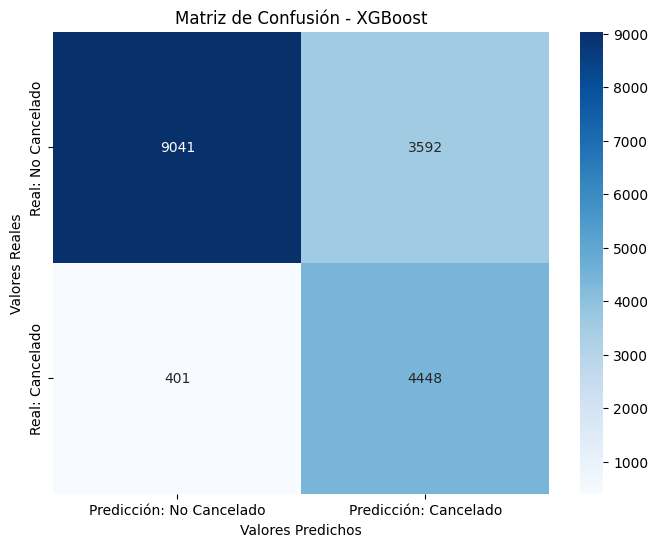

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm_xgb, annot=True, fmt='g', cmap='Blues',
            xticklabels=['Predicción: No Cancelado', 'Predicción: Cancelado'],
            yticklabels=['Real: No Cancelado', 'Real: Cancelado'])
plt.title('Matriz de Confusión - XGBoost')
plt.ylabel('Valores Reales')
plt.xlabel('Valores Predichos')
plt.show()